# EDA 3. Credit Card Transactions Fraud Detection (Sparkov)

Проект: обнаружение мошеннических транзакций в условиях сильного дисбаланса классов.

Данные: [Kaggle – kartik2112/fraud-detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection). Данные сгенерированы симулятором [Sparkov Data Generation](https://github.com/namebrandon/Sparkov_Data_Generation) на основе профилей клиентов и мерчантов. Около 1.85 млн операций по картам 1000 клиентов у 800 мерчантов в США с 1 января 2019 по 31 декабря 2020. Авторы уже разделили данные по времени на `fraudTrain.csv` (до 21.06.2020) и `fraudTest.csv` (после). В нашей версии файлов есть еще столбец `merch_zipcode`, которого нет в исходной версии на Kaggle.

Признаки:
- про операцию: `trans_date_trans_time`, `unix_time`, `amt`, `category`, `merchant`, `trans_num`
- про карту и клиента: `cc_num`, `first`, `last`, `gender`, `dob`, `job`, `street`, `city`, `state`, `zip`, `lat`, `long`, `city_pop`
- про мерчанта: `merchant`, `merch_lat`, `merch_long`, `merch_zipcode`
- таргет: `is_fraud`

Главное отличие от ULB и PaySim: тут есть id карты и вся история ее операций за два года. Значит, можно делать поведенческие признаки (насколько сумма отличается от обычной для карты, как часто идут операции), смотреть контекстные аномалии и учитывать группы при разбиении.

Файлы `fraudTrain.csv` и `fraudTest.csv` кладем в папку `data/`. EDA делаем на train, а test используем только чтобы проверить сдвиг распределений.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import IsolationForest

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
PAL = {0: '#4C72B0', 1: '#D1495B'}
RS = 42

## 1. Загрузка и общий обзор

In [2]:
tr = pd.read_csv('data/fraudTrain.csv')
te = pd.read_csv('data/fraudTest.csv')
print('train:', tr.shape, 'test:', te.shape)
tr.head()

train: (1296675, 24) test: (555719, 24)


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,merch_zipcode
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,28705.0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,NaN
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,83236.0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,NaN
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,22844.0


In [3]:
tr.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 24 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  str    
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  str    
 4   category               1296675 non-null  str    
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  str    
 7   last                   1296675 non-null  str    
 8   gender                 1296675 non-null  str    
 9   street                 1296675 non-null  str    
 10  city                   1296675 non-null  str    
 11  state                  1296675 non-null  str    
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long                   129667

In [4]:
tr.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1296675.0,NaN,NaN,NaN,648337.0,374317.974488,0.0,324168.5,648337.0,972505.5,1296674.0
trans_date_trans_time,1296675,1274791,2019-04-22 16:02:01,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cc_num,1296675.0,NaN,NaN,NaN,417192042079726656.0,1308806447000240384.0,60416207185.0,180042946491150.0,3521417320836166.0,4642255475285942.0,4992346398065154048.0
merchant,1296675,693,fraud_Kilback LLC,4403,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1296675,14,gas_transport,131659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amt,1296675.0,NaN,NaN,NaN,70.351035,160.316039,1.0,9.65,47.52,83.14,28948.9
first,1296675,352,Christopher,26669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last,1296675,481,Smith,28794,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1296675,2,F,709863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street,1296675,983,864 Reynolds Plains,3123,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Что видно из describe:
- 1 296 675 операций в train и 555 719 в test, 24 столбца, 12 строковых и 12 числовых
- `Unnamed: 0` это сохраненный индекс, а `trans_num` уникален для каждой операции, это id, а не признаки
- 983 карты (`cc_num`), 693 мерчанта, 14 категорий, 51 штат (вместе с DC)
- `amt` от 1 до 28 949, медиана 47, среднее 70. Хвост тяжелый, но не такой, как в PaySim
- `city_pop` от 23 до 2.9 млн, медиана 2 456, то есть большинство клиентов из маленьких городов
- пропуски есть только в `merch_zipcode` (count меньше числа строк)
- `cc_num` и `zip` хоть и числа, но по сути коды, их среднее и std смысла не имеют

## 2. Целевая переменная и степень дисбаланса

In [5]:
for name, d in [('train', tr), ('test', te)]:
    c = d['is_fraud'].value_counts().sort_index()
    print(name, 'легитимных:', c[0], 'мошеннических:', c[1], 'доля:', round(c[1] / len(d), 5), 'соотношение 1 :', round(c[0] / c[1]))

train легитимных: 1289169 мошеннических: 7506 доля: 0.00579 соотношение 1 : 172
test легитимных: 553574 мошеннических: 2145 доля: 0.00386 соотношение 1 : 258


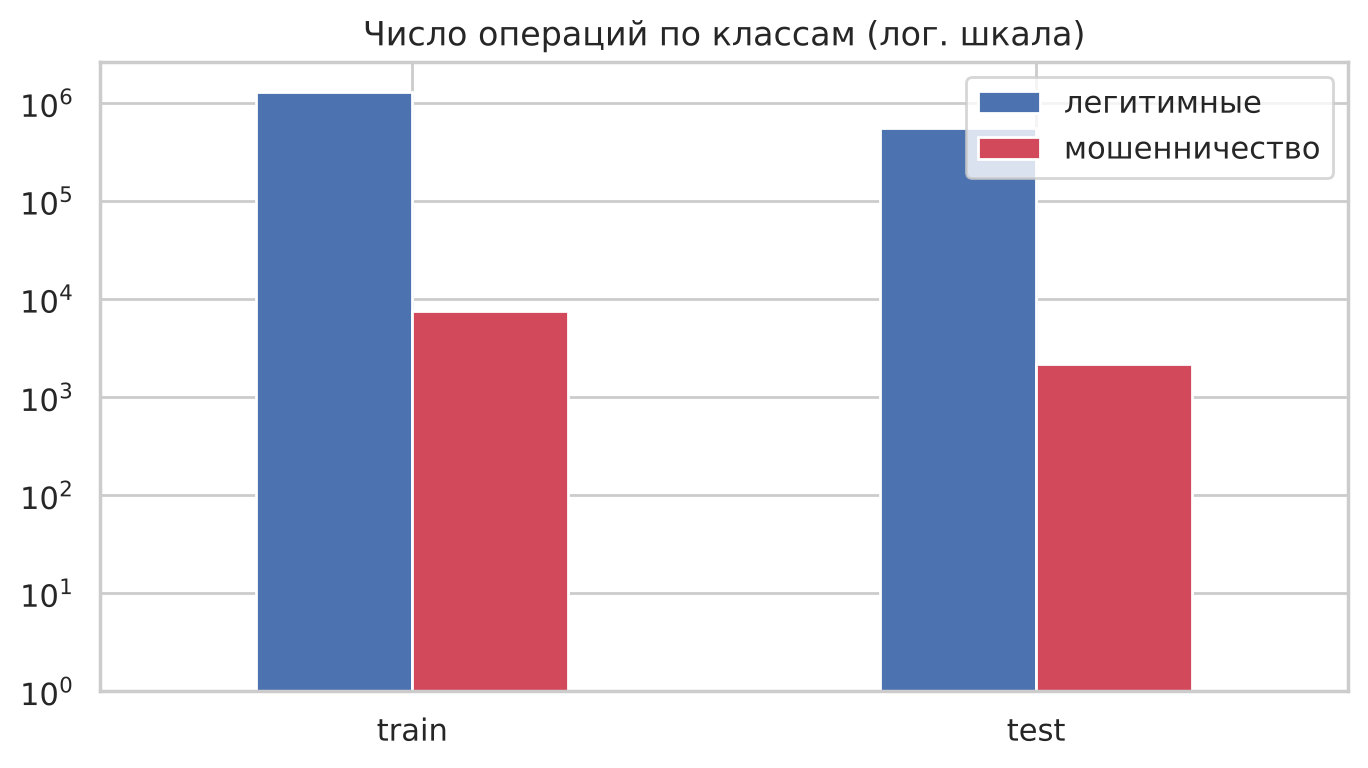

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
x = pd.DataFrame({'train': tr['is_fraud'].value_counts(), 'test': te['is_fraud'].value_counts()}).T
x.columns = ['легитимные', 'мошенничество']
x.plot.bar(ax=ax, color=[PAL[0], PAL[1]], log=True)
ax.set_title('Число операций по классам (лог. шкала)')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

Мошенничества 0.58% в train и 0.39% в test. Дисбаланс мягче, чем в ULB и PaySim, но все равно сильный (1 к 172 и 1 к 258). Важно, что доля класса в train и test отличается в 1.5 раза. Модель, откалиброванная на train, будет на test переоценивать вероятность мошенничества, и precision при выбранном пороге упадет. Получается естественная проверка устойчивости к изменению доли мошенничества.

## 3. Пропущенные значения

In [7]:
na = pd.DataFrame({'train_missing': tr.isna().sum(), 'train_share': tr.isna().mean(),
                   'test_missing': te.isna().sum(), 'test_share': te.isna().mean()})
print('Доля пропущенных ячеек в train:', round(tr.isna().sum().sum() / tr.size, 5))
na[na['train_missing'] > 0]

Доля пропущенных ячеек в train: 0.0063


,train_missing,train_share,test_missing,test_share
merch_zipcode,195973,0.151135,83983,0.151125


Пропуски есть только в `merch_zipcode`, примерно 15% строк и в train, и в test. В целом таблица почти без пропусков (0.6% ячеек).

Гипотеза. В Sparkov координаты мерчанта получаются случайным сдвигом от координат клиента, а индекс мерчанта, похоже, потом определяли по этим координатам. Если случайная точка не попала ни в одну зону почтового индекса (пустая местность, вода, горы), индекс не нашелся. Если это так, то:
1. пропусков должно быть больше в малонаселенных штатах запада и там, где точка может попасть в воду (острова, побережье)
2. пропуски не должны зависеть от категории, суммы и класса операции

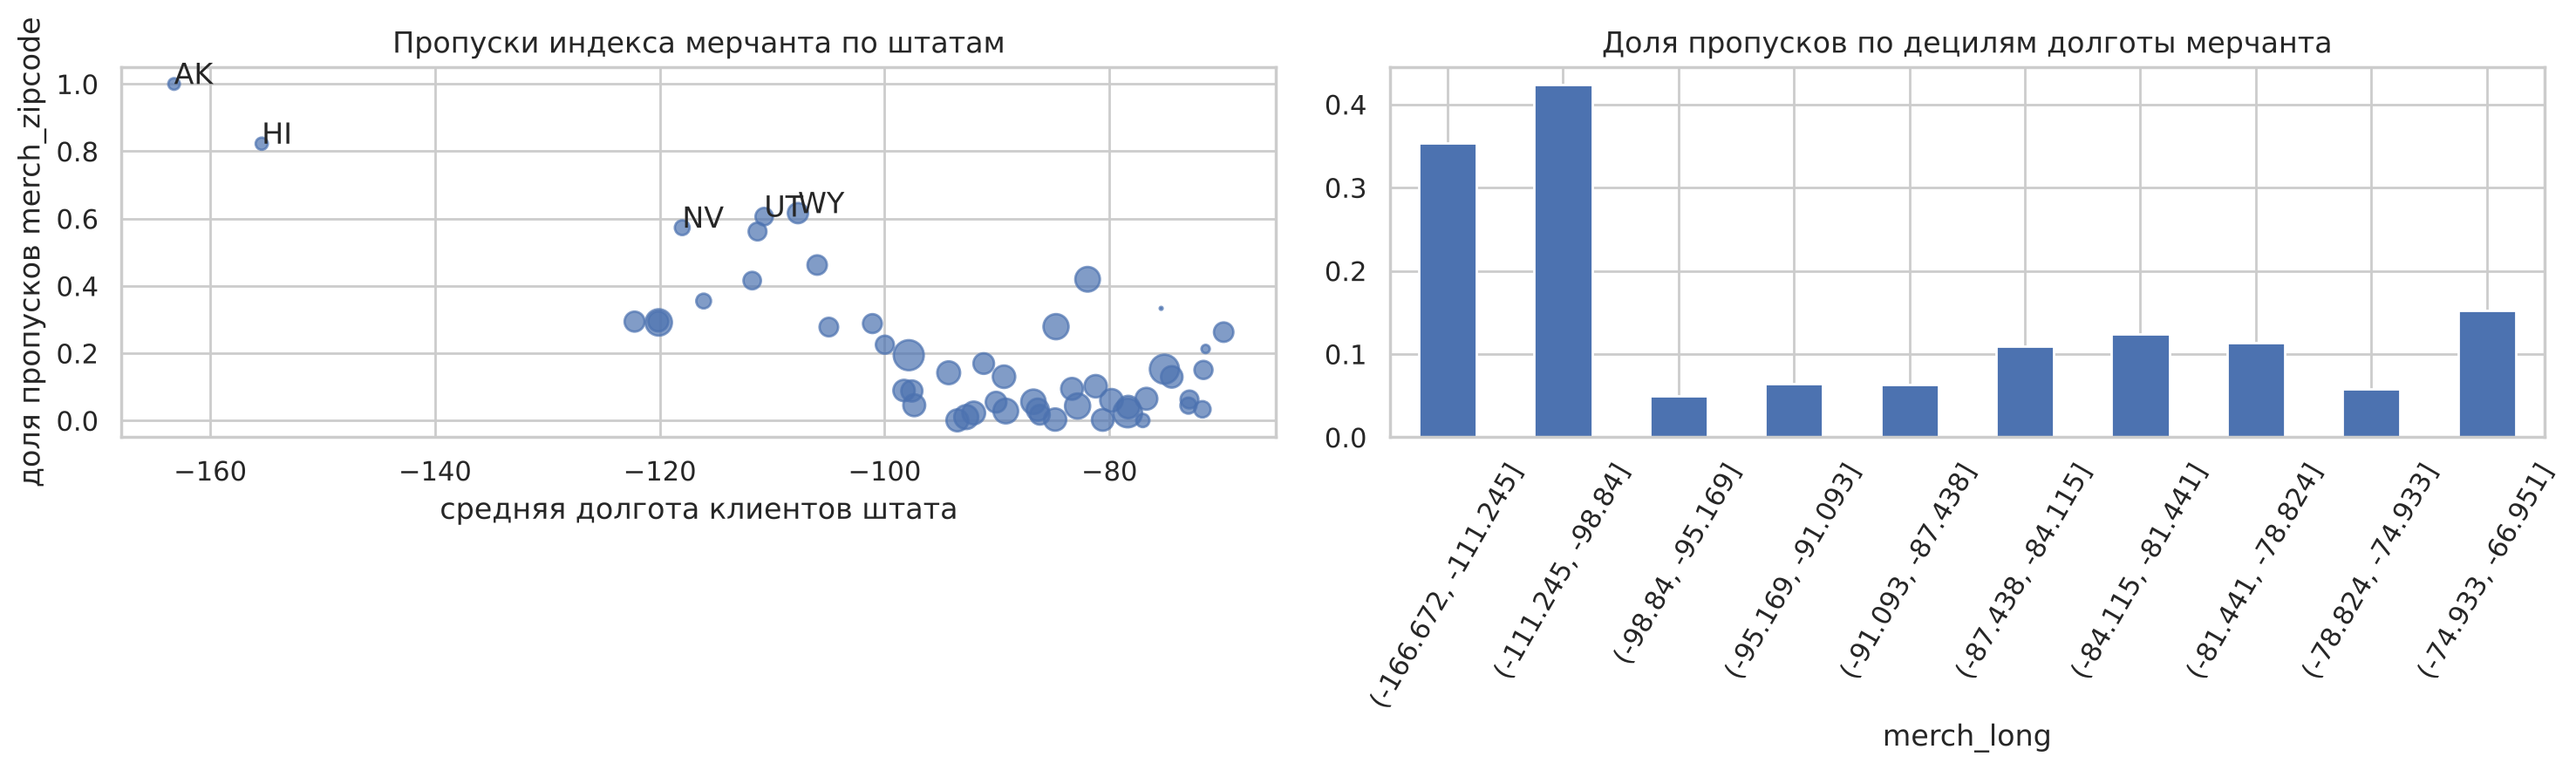

In [8]:
tr['zip_missing'] = tr['merch_zipcode'].isna()
st = tr.groupby('state').agg(missing_share=('zip_missing', 'mean'), n=('zip_missing', 'size'), mean_long=('long', 'mean'))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].scatter(st['mean_long'], st['missing_share'], s=np.sqrt(st['n']) / 2, color=PAL[0], alpha=0.7)
for s_, r in st.sort_values('missing_share').tail(5).iterrows():
    axes[0].annotate(s_, (r['mean_long'], r['missing_share']))
axes[0].set_xlabel('средняя долгота клиентов штата')
axes[0].set_ylabel('доля пропусков merch_zipcode')
axes[0].set_title('Пропуски индекса мерчанта по штатам')
lb = pd.qcut(tr['merch_long'], 10)
tr.groupby(lb, observed=True)['zip_missing'].mean().plot.bar(ax=axes[1], color=PAL[0])
axes[1].set_title('Доля пропусков по децилям долготы мерчанта')
axes[1].tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

In [9]:
print('Доля мошенничества при наличии индекса:', round(tr.loc[~tr['zip_missing'], 'is_fraud'].mean(), 5))
print('Доля мошенничества при пропуске индекса:', round(tr.loc[tr['zip_missing'], 'is_fraud'].mean(), 5))
ct = pd.crosstab(tr['zip_missing'], tr['is_fraud'])
print('chi2 p-value (связь с таргетом):', stats.chi2_contingency(ct)[1])
ct2 = pd.crosstab(tr['zip_missing'], tr['category'])
print('chi2 p-value (связь с категорией):', stats.chi2_contingency(ct2)[1])
print('Медиана суммы:', tr.groupby('zip_missing')['amt'].median().to_dict())
print('Медиана city_pop:', tr.groupby('zip_missing')['city_pop'].median().to_dict())

Доля мошенничества при наличии индекса: 0.00578
Доля мошенничества при пропуске индекса: 0.00583
chi2 p-value (связь с таргетом): 0.7939742891008155


chi2 p-value (связь с категорией): 4.813765555957612e-10
Медиана суммы: {False: 47.54, True: 47.4}
Медиана city_pop: {False: 2456.0, True: 2408.0}


Похоже, гипотеза верная. Больше всего пропусков на Аляске (100%), на Гавайях (82%) и в горных штатах запада (NV, UT, WY, около 60%), и еще их больше на атлантическом побережье (самый восточный дециль по долготе). То есть там, где случайная точка попадает в пустую местность или в океан. Доля мошенничества с пропуском и без одинаковая (p-value 0.79), медианы суммы и `city_pop` тоже совпадают. С категорией связь формально значимая, но это из-за огромной выборки, доли категорий отличаются на десятые доли процента.

Что делаем: `merch_zipcode` ничего не добавляет к `merch_lat` и `merch_long` (он из них и получен) и с таргетом не связан, поэтому просто удаляем столбец. Заполнять медианой или ближайшим индексом нет смысла.

Еще, когда будем делать поведенческие признаки (раздел 6), появятся структурные пропуски: у первой операции карты нет предыдущей. Их оставим NaN, XGBoost с ними справится.

## 4. Ошибочные значения

In [10]:
tr['ts'] = pd.to_datetime(tr['trans_date_trans_time'])
tr['dob'] = pd.to_datetime(tr['dob'])
tr['age'] = (tr['ts'] - tr['dob']).dt.days / 365.25
shift = (tr['ts'] - pd.to_datetime(tr['unix_time'], unit='s')).dt.total_seconds() / 86400
checks = pd.Series({
    'is_fraud вне {0, 1}': (~tr['is_fraud'].isin([0, 1])).sum(),
    'amt <= 0': (tr['amt'] <= 0).sum(),
    'возраст < 13 или > 100': ((tr['age'] < 13) | (tr['age'] > 100)).sum(),
    'координаты клиента вне США': (~tr['lat'].between(18, 72) | ~tr['long'].between(-180, -65)).sum(),
    'city_pop <= 0': (tr['city_pop'] <= 0).sum(),
    'дубликаты trans_num': tr['trans_num'].duplicated().sum(),
    'дубликаты без идентификаторов': tr.drop(columns=['Unnamed: 0', 'trans_num']).duplicated().sum(),
    'merchant без префикса fraud_': (~tr['merchant'].str.startswith('fraud_')).sum(),
})
checks.to_frame('n_rows')

,n_rows
"is_fraud вне {0, 1}",0
amt <= 0,0
возраст < 13 или > 100,0
координаты клиента вне США,0
city_pop <= 0,0
дубликаты trans_num,0
дубликаты без идентификаторов,0
merchant без префикса fraud_,0


In [11]:
print('Расхождение trans_date_trans_time и unix_time, дней:', shift.round(2).value_counts().to_dict())
print('unix_time как дата, минимум:', pd.to_datetime(tr['unix_time'], unit='s').min())
cust = tr.groupby('cc_num')[['first', 'last', 'gender', 'dob', 'street', 'zip', 'job']].nunique().max()
print('Максимум различных значений атрибутов клиента на одну карту:', cust.to_dict())
print('Возраст клиента, лет: от', round(tr['age'].min(), 1), 'до', round(tr['age'].max(), 1))
print('Сдвиг координат мерчанта от клиента, градусы: lat', round((tr['merch_lat'] - tr['lat']).abs().max(), 3),
      'long', round((tr['merch_long'] - tr['long']).abs().max(), 3))

Расхождение trans_date_trans_time и unix_time, дней: {2556.0: 924311, 2557.0: 372364}
unix_time как дата, минимум: 2012-01-01 00:00:18


Максимум различных значений атрибутов клиента на одну карту: {'first': 1, 'last': 1, 'gender': 1, 'dob': 1, 'street': 1, 'zip': 1, 'job': 1}
Возраст клиента, лет: от 13.9 до 95.6
Сдвиг координат мерчанта от клиента, градусы: lat 1.0 long 1.0


Что нашли:
- `unix_time` не совпадает с датой операции, сдвиг 2556–2557 дней, примерно 7 лет (по `unix_time` получаются 2012–2013 годы). Разница в сутки между частями строк, видимо, из-за високосных лет. Это ошибка генерации, поэтому дату берем из `trans_date_trans_time`, а `unix_time` можно использовать только для разниц во времени внутри карты или вообще удалить.
- У всех мерчантов в названии есть префикс `fraud_`. Это артефакт генератора, а не утечка, он есть у 100% строк, включая нормальные. Просто удаляем префикс.
- Данные клиента внутри одной карты не меняются (одно имя, дата рождения, адрес на `cc_num`), противоречий нет.
- Возраст от 13.9 до 95.6 лет, выглядит правдоподобно (около 14 лет может быть у держателя дополнительной карты).
- Координаты мерчанта отличаются от координат клиента максимум на 1 градус по каждой оси. Это правило генератора, все покупки "рядом с домом", поэтому расстояние до мерчанта, скорее всего, ничего не дает (проверим ниже).
- Отрицательных и нулевых сумм, дубликатов и невозможных значений нет.

In [12]:
tr['merchant'] = tr['merchant'].str.replace('fraud_', '', regex=False)
tr = tr.drop(columns=['Unnamed: 0', 'merch_zipcode'])

## 5. Выбросы

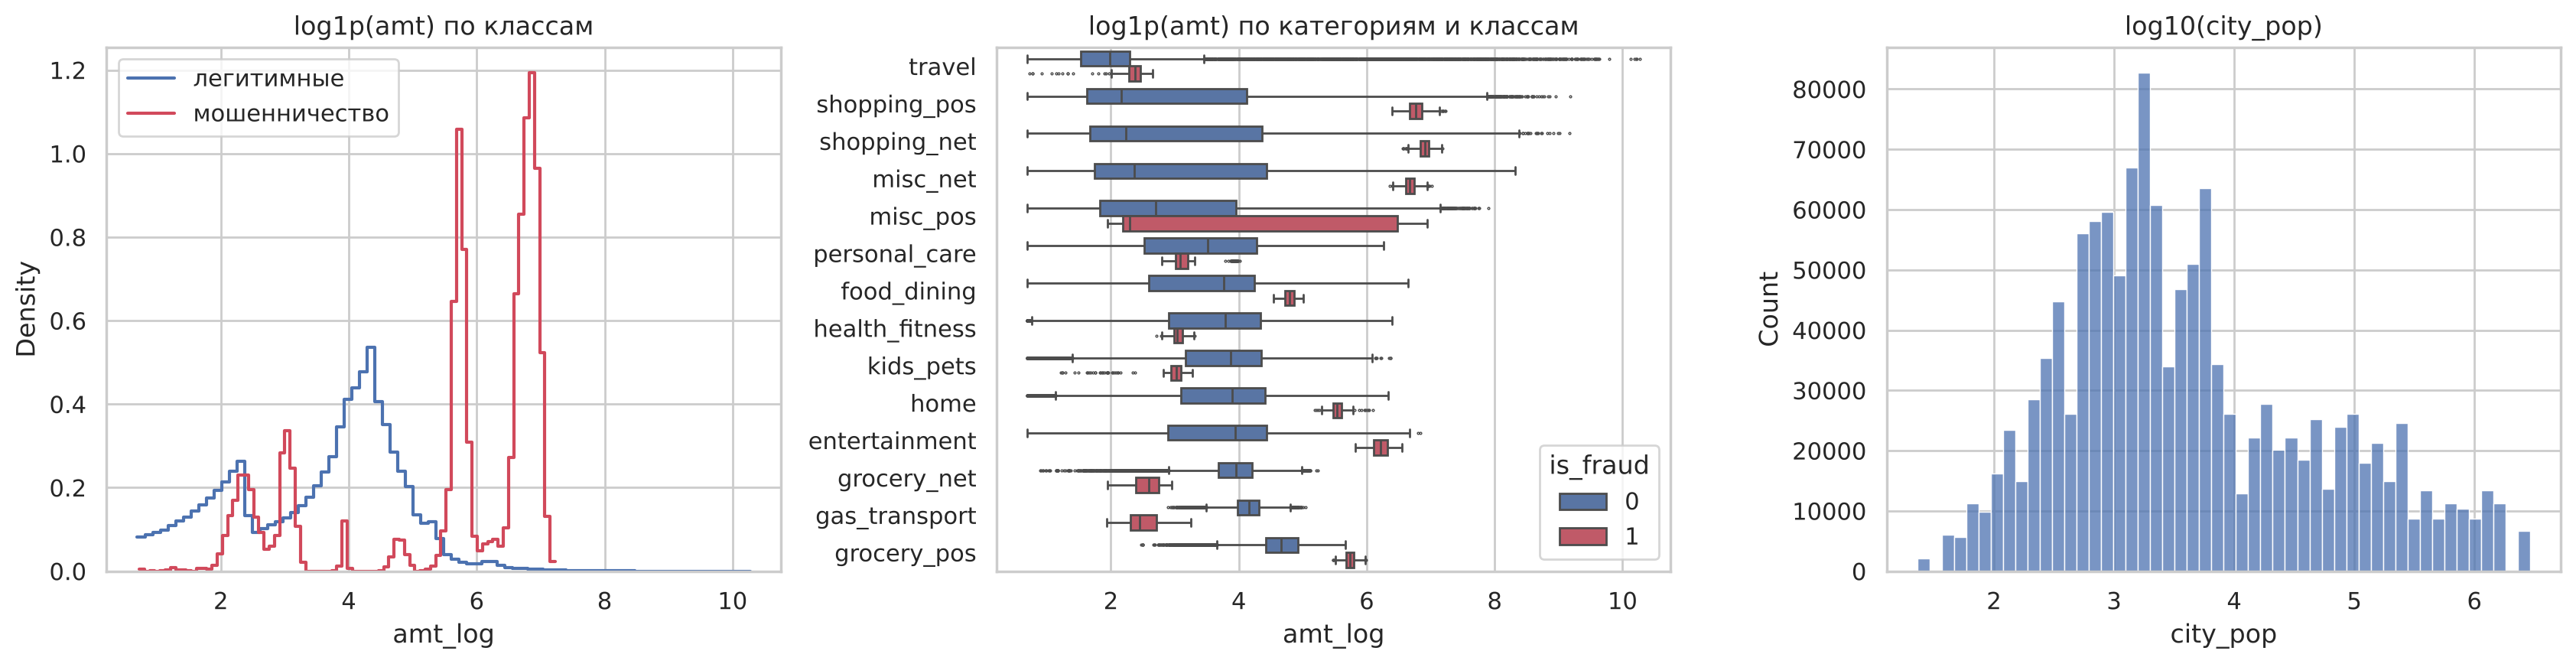

In [13]:
tr['amt_log'] = np.log1p(tr['amt'])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for cls in [0, 1]:
    sns.histplot(tr.loc[tr['is_fraud'] == cls, 'amt_log'], bins=80, stat='density', element='step', fill=False,
                 color=PAL[cls], ax=axes[0], label=['легитимные', 'мошенничество'][cls])
axes[0].legend()
axes[0].set_title('log1p(amt) по классам')
sns.boxplot(data=tr, y='category', x='amt_log', hue='is_fraud', palette=PAL, ax=axes[1], fliersize=0.5,
            order=tr.groupby('category')['amt'].median().sort_values().index)
axes[1].set_title('log1p(amt) по категориям и классам')
axes[1].set_ylabel('')
sns.histplot(np.log10(tr['city_pop']), bins=50, ax=axes[2], color=PAL[0])
axes[2].set_title('log10(city_pop)')
plt.tight_layout()
plt.show()

In [14]:
def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

rows = []
for c in ['amt', 'city_pop', 'age']:
    m = iqr_mask(tr[c])
    rows.append({'feature': c, 'outlier_share': m.mean(), 'fraud_rate_outliers': tr.loc[m, 'is_fraud'].mean(),
                 'fraud_rate_inliers': tr.loc[~m, 'is_fraud'].mean(), 'skew': tr[c].skew(), 'max': tr[c].max()})
pd.DataFrame(rows).set_index('feature').round(4)

,outlier_share,fraud_rate_outliers,fraud_rate_inliers,skew,max
feature,,,,,
amt,0.0519,0.0848,0.0015,42.2779,2.894890e+04
city_pop,0.1872,0.0059,0.0058,5.5939,2.906700e+06
age,0.0008,0.0000,0.0058,0.6116,9.563860e+01


In [15]:
cat_q = tr[tr['is_fraud'] == 0].groupby('category')['amt'].quantile(0.99).rename('legit_p99')
tr = tr.join(cat_q, on='category')
tr['amt_over_cat_p99'] = tr['amt'] > tr['legit_p99']
print('Мошеннических операций с суммой выше 99-го перцентиля легитимных в своей категории:', round(tr.loc[tr['is_fraud'] == 1, 'amt_over_cat_p99'].mean(), 3))
print('Максимальная мошенническая сумма:', tr.loc[tr['is_fraud'] == 1, 'amt'].max())
print('Легитимных операций дороже максимальной мошеннической:', (tr.loc[tr['is_fraud'] == 0, 'amt'] > tr.loc[tr['is_fraud'] == 1, 'amt'].max()).sum())
tr.groupby(['category', 'is_fraud'])['amt'].median().unstack().round(1).rename(columns={0: 'median_legit', 1: 'median_fraud'})

Мошеннических операций с суммой выше 99-го перцентиля легитимных в своей категории: 0.575
Максимальная мошенническая сумма: 1376.04
Легитимных операций дороже максимальной мошеннической: 1575


is_fraud,median_legit,median_fraud
category,,
entertainment,50.6,498.9
food_dining,41.9,119.4
gas_transport,62.9,10.6
grocery_net,51.0,12.4
grocery_pos,104.6,310.0
health_fitness,42.9,19.8
home,48.2,252.2
kids_pets,47.2,19.5
misc_net,9.7,792.3


- У `amt` тяжелый правый хвост, около 5% выбросов по IQR, и среди них мошенничество встречается сильно чаще (8.5% против 0.15%). В логарифме у мошенничества два пика: маленькие суммы (до 20) и широкий пик от сотен до тысячи.
- Мошенническая сумма ограничена сверху, максимум 1376, а у нормальных операций есть суммы до 28 949. То есть самые крупные операции нормальные, и методы поиска аномалий будут на них ложно срабатывать.
- Важно смотреть на сумму внутри категории. В `shopping_net`, `shopping_pos`, `misc_net` медианная сумма мошенничества в 80–120 раз больше медианы нормальных операций, а в `gas_transport`, `grocery_net`, `kids_pets`, `personal_care` мошенничество, наоборот, мелкое, около 10–20 (похоже на проверку карты). 57.5% мошеннических операций дороже 99-го перцентиля нормальных операций своей категории. То есть большая часть мошенничества это выбросы внутри категории, но не по всему датасету.
- `city_pop` сильно скошен (большие города выглядят выбросами), но с мошенничеством это не связано, берем `log10`.

Выбросы не удаляем. Сумму используем в логарифме, а еще относительно категории и истории карты (раздел 6).

## 6. Признаки по отдельности и связь с целевой переменной

### 6.1. Время

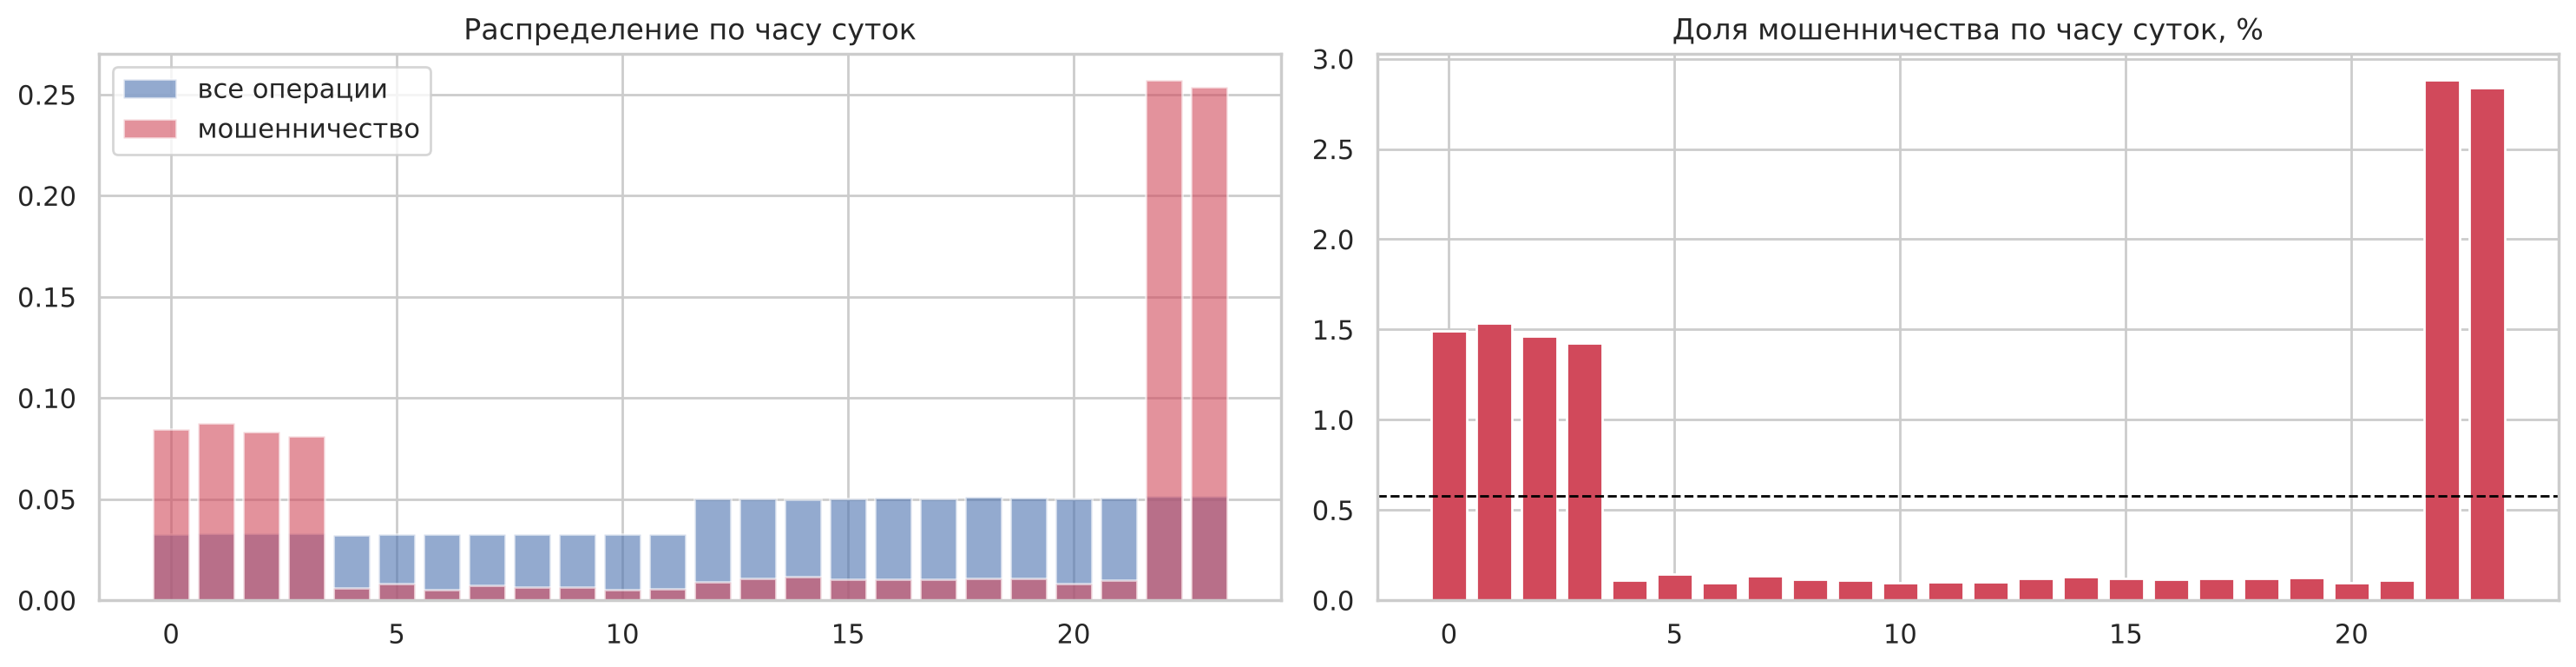

In [16]:
tr['hour'] = tr['ts'].dt.hour
tr['dow'] = tr['ts'].dt.dayofweek
tr['month'] = tr['ts'].dt.to_period('M')
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
h = tr.groupby('hour')['is_fraud'].agg(['size', 'sum'])
axes[0].bar(h.index, h['size'] / h['size'].sum(), color=PAL[0], alpha=0.6, label='все операции')
axes[0].bar(h.index, h['sum'] / h['sum'].sum(), color=PAL[1], alpha=0.6, label='мошенничество')
axes[0].legend()
axes[0].set_title('Распределение по часу суток')
axes[1].bar(h.index, h['sum'] / h['size'] * 100, color=PAL[1])
axes[1].axhline(tr['is_fraud'].mean() * 100, color='black', ls='--', lw=1)
axes[1].set_title('Доля мошенничества по часу суток, %')
plt.tight_layout()
plt.show()

Почти все мошенничество в двух окнах: 22–23 часа и 0–3 часа. В эти часы мошенничества 1.4–2.9%, а в остальное время около 0.1%, то есть в 15–25 раз меньше. Время суток один из главных признаков. Связь немонотонная, поэтому одномерный ROC-AUC у `hour` небольшой, а для линейных моделей час надо кодировать (окнами или через sin/cos).

### 6.2. Категория, пол, возраст, география

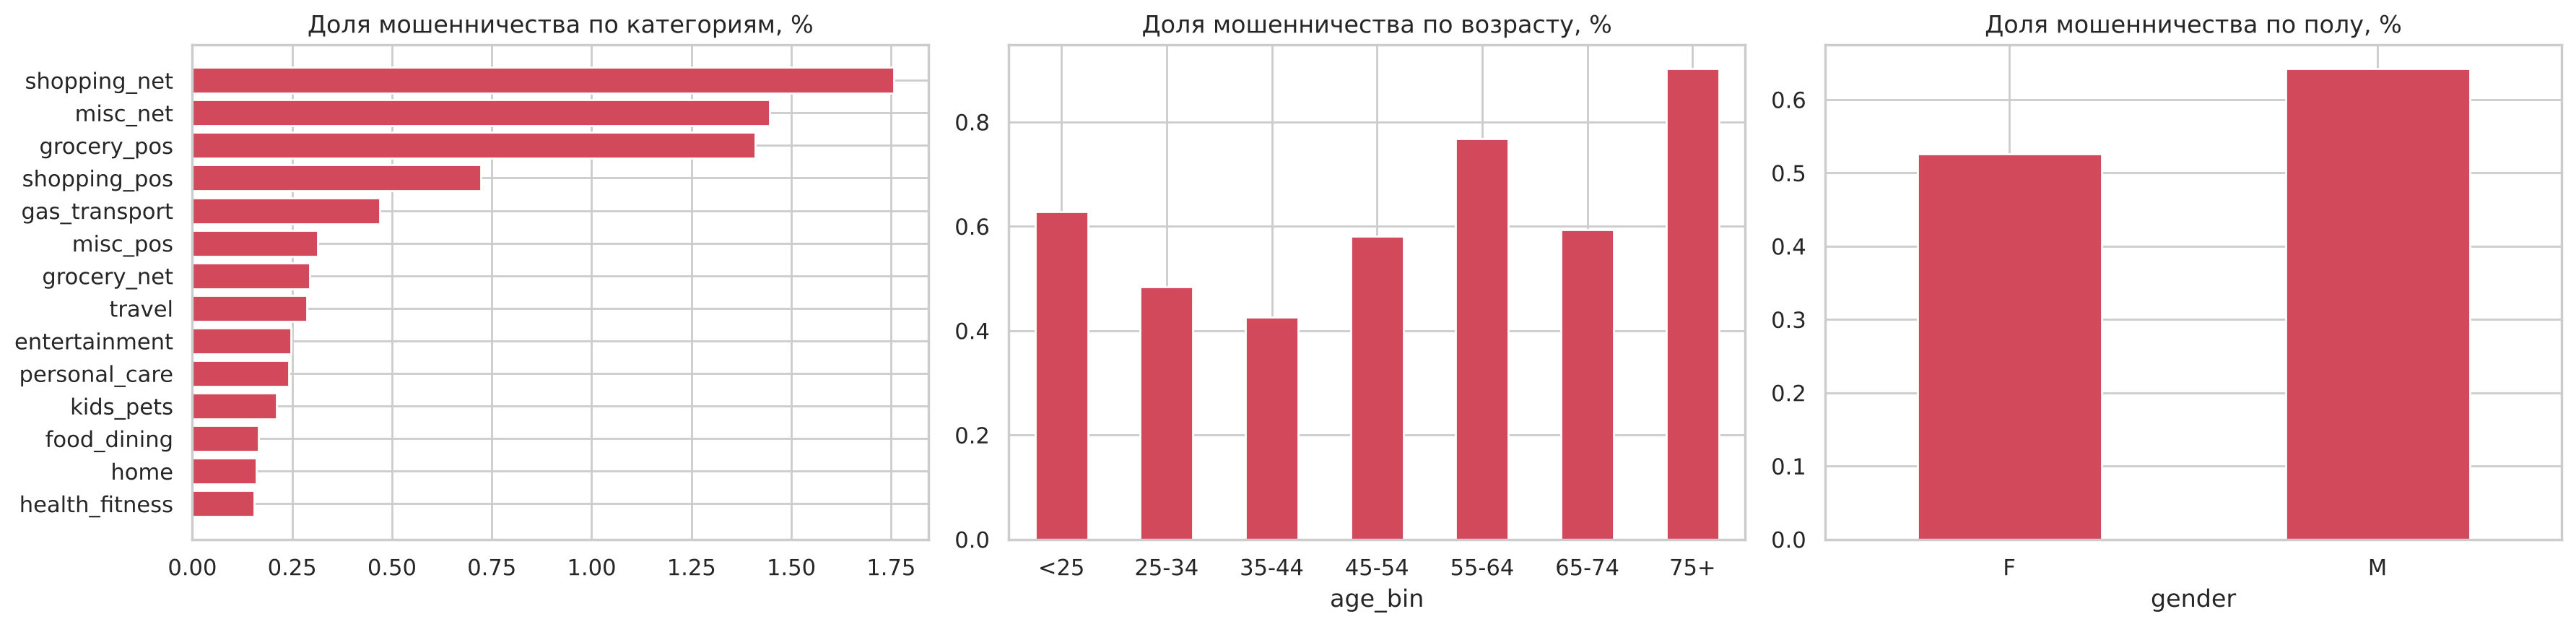

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
cat = tr.groupby('category')['is_fraud'].agg(['mean', 'size']).sort_values('mean')
axes[0].barh(cat.index, cat['mean'] * 100, color=PAL[1])
axes[0].set_title('Доля мошенничества по категориям, %')
tr['age_bin'] = pd.cut(tr['age'], [0, 25, 35, 45, 55, 65, 75, 120], labels=['<25', '25-34', '35-44', '45-54', '55-64', '65-74', '75+'])
(tr.groupby('age_bin', observed=True)['is_fraud'].mean() * 100).plot.bar(ax=axes[1], color=PAL[1])
axes[1].set_title('Доля мошенничества по возрасту, %')
axes[1].tick_params(axis='x', rotation=0)
(tr.groupby('gender')['is_fraud'].mean() * 100).plot.bar(ax=axes[2], color=PAL[1])
axes[2].set_title('Доля мошенничества по полу, %')
axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [18]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

tr['dist_km'] = haversine(tr['lat'], tr['long'], tr['merch_lat'], tr['merch_long'])
tr['city_pop_log'] = np.log10(tr['city_pop'])
st = tr.groupby('state')['is_fraud'].agg(['mean', 'size', 'sum'])
print('Штаты с наименьшим числом операций:')
print(st.sort_values('size').head(5))

Штаты с наименьшим числом операций:
           mean  size  sum
state                     
DE     1.000000     9    9
RI     0.027273   550   15
AK     0.016981  2120   36
HI     0.002735  2559    7
DC     0.005812  3613   21


### 6.3. Поведенческие признаки по истории карты

Главный плюс датасета это id карты. Сделаем признаки, которые используют только прошлые операции той же карты, чтобы не было утечки:
- `hours_since_prev` – сколько часов прошло с предыдущей операции
- `amt_ratio` – сумма, деленная на среднюю сумму всех прошлых операций карты
- `n_prev_24h` – сколько операций по карте было за последние 24 часа
- `cat_amt_z` – насколько сумма отличается от прошлых сумм этой карты в этой категории (в стандартных отклонениях)

In [19]:
tr = tr.sort_values(['cc_num', 'ts']).reset_index(drop=True)
g = tr.groupby('cc_num')
tr['hours_since_prev'] = g['ts'].diff().dt.total_seconds() / 3600
n_prev = g.cumcount()
tr['amt_mean_prev'] = (g['amt'].cumsum() - tr['amt']) / n_prev.replace(0, np.nan)
tr['amt_ratio'] = tr['amt'] / tr['amt_mean_prev']
tr['n_prev_24h'] = tr.set_index('ts').groupby('cc_num')['amt'].rolling('24h', closed='left').count().to_numpy()
gc = tr.groupby(['cc_num', 'category'])
n_cat = gc.cumcount()
s1 = gc['amt'].cumsum() - tr['amt']
s2 = gc['amt'].transform(lambda x: (x ** 2).cumsum()) - tr['amt'] ** 2
mu = s1 / n_cat.replace(0, np.nan)
sd = np.sqrt((s2 / n_cat.replace(0, np.nan) - mu ** 2).clip(lower=0))
tr['cat_amt_z'] = (tr['amt'] - mu) / sd.where(n_cat >= 5).replace(0, np.nan)
beh = ['hours_since_prev', 'amt_ratio', 'n_prev_24h', 'cat_amt_z']
tr[beh].isna().mean().rename('share_missing').to_frame().T

,hours_since_prev,amt_ratio,n_prev_24h,cat_amt_z
share_missing,0.000758,0.000758,0.083999,0.049529


In [20]:
pos = tr['is_fraud'] == 1
feats = ['amt', 'hour', 'age', 'city_pop_log', 'dist_km', 'lat', 'long', 'hours_since_prev', 'amt_ratio', 'n_prev_24h', 'cat_amt_z']
rows = []
for c in feats:
    x = tr[c]
    ok = x.notna()
    auc = roc_auc_score(tr.loc[ok, 'is_fraud'], x[ok])
    rows.append({'feature': c, 'roc_auc_1d': max(auc, 1 - auc), 'direction': '+' if auc >= 0.5 else '-',
                 'pr_auc_1d': average_precision_score(tr.loc[ok, 'is_fraud'], x[ok] if auc >= 0.5 else -x[ok]),
                 'ks': stats.ks_2samp(x[ok & pos], x[ok & ~pos]).statistic,
                 'median_legit': x[~pos].median(), 'median_fraud': x[pos].median()})
sep = pd.DataFrame(rows).set_index('feature').sort_values('roc_auc_1d', ascending=False)
sep.round(3)

,roc_auc_1d,direction,pr_auc_1d,ks,median_legit,median_fraud
feature,,,,,,
amt,0.835,+,0.187,0.726,47.280,396.505
amt_ratio,0.807,+,0.137,0.630,0.664,5.230
cat_amt_z,0.804,+,0.125,0.674,-0.267,3.899
hours_since_prev,0.649,-,0.014,0.291,4.618,1.363
hour,0.585,+,0.018,0.410,14.000,22.000
n_prev_24h,0.551,+,0.007,0.105,4.000,4.000
age,0.543,+,0.007,0.107,43.956,47.803
long,0.512,+,0.006,0.032,-87.477,-86.692
city_pop_log,0.505,+,0.006,0.021,3.390,3.419


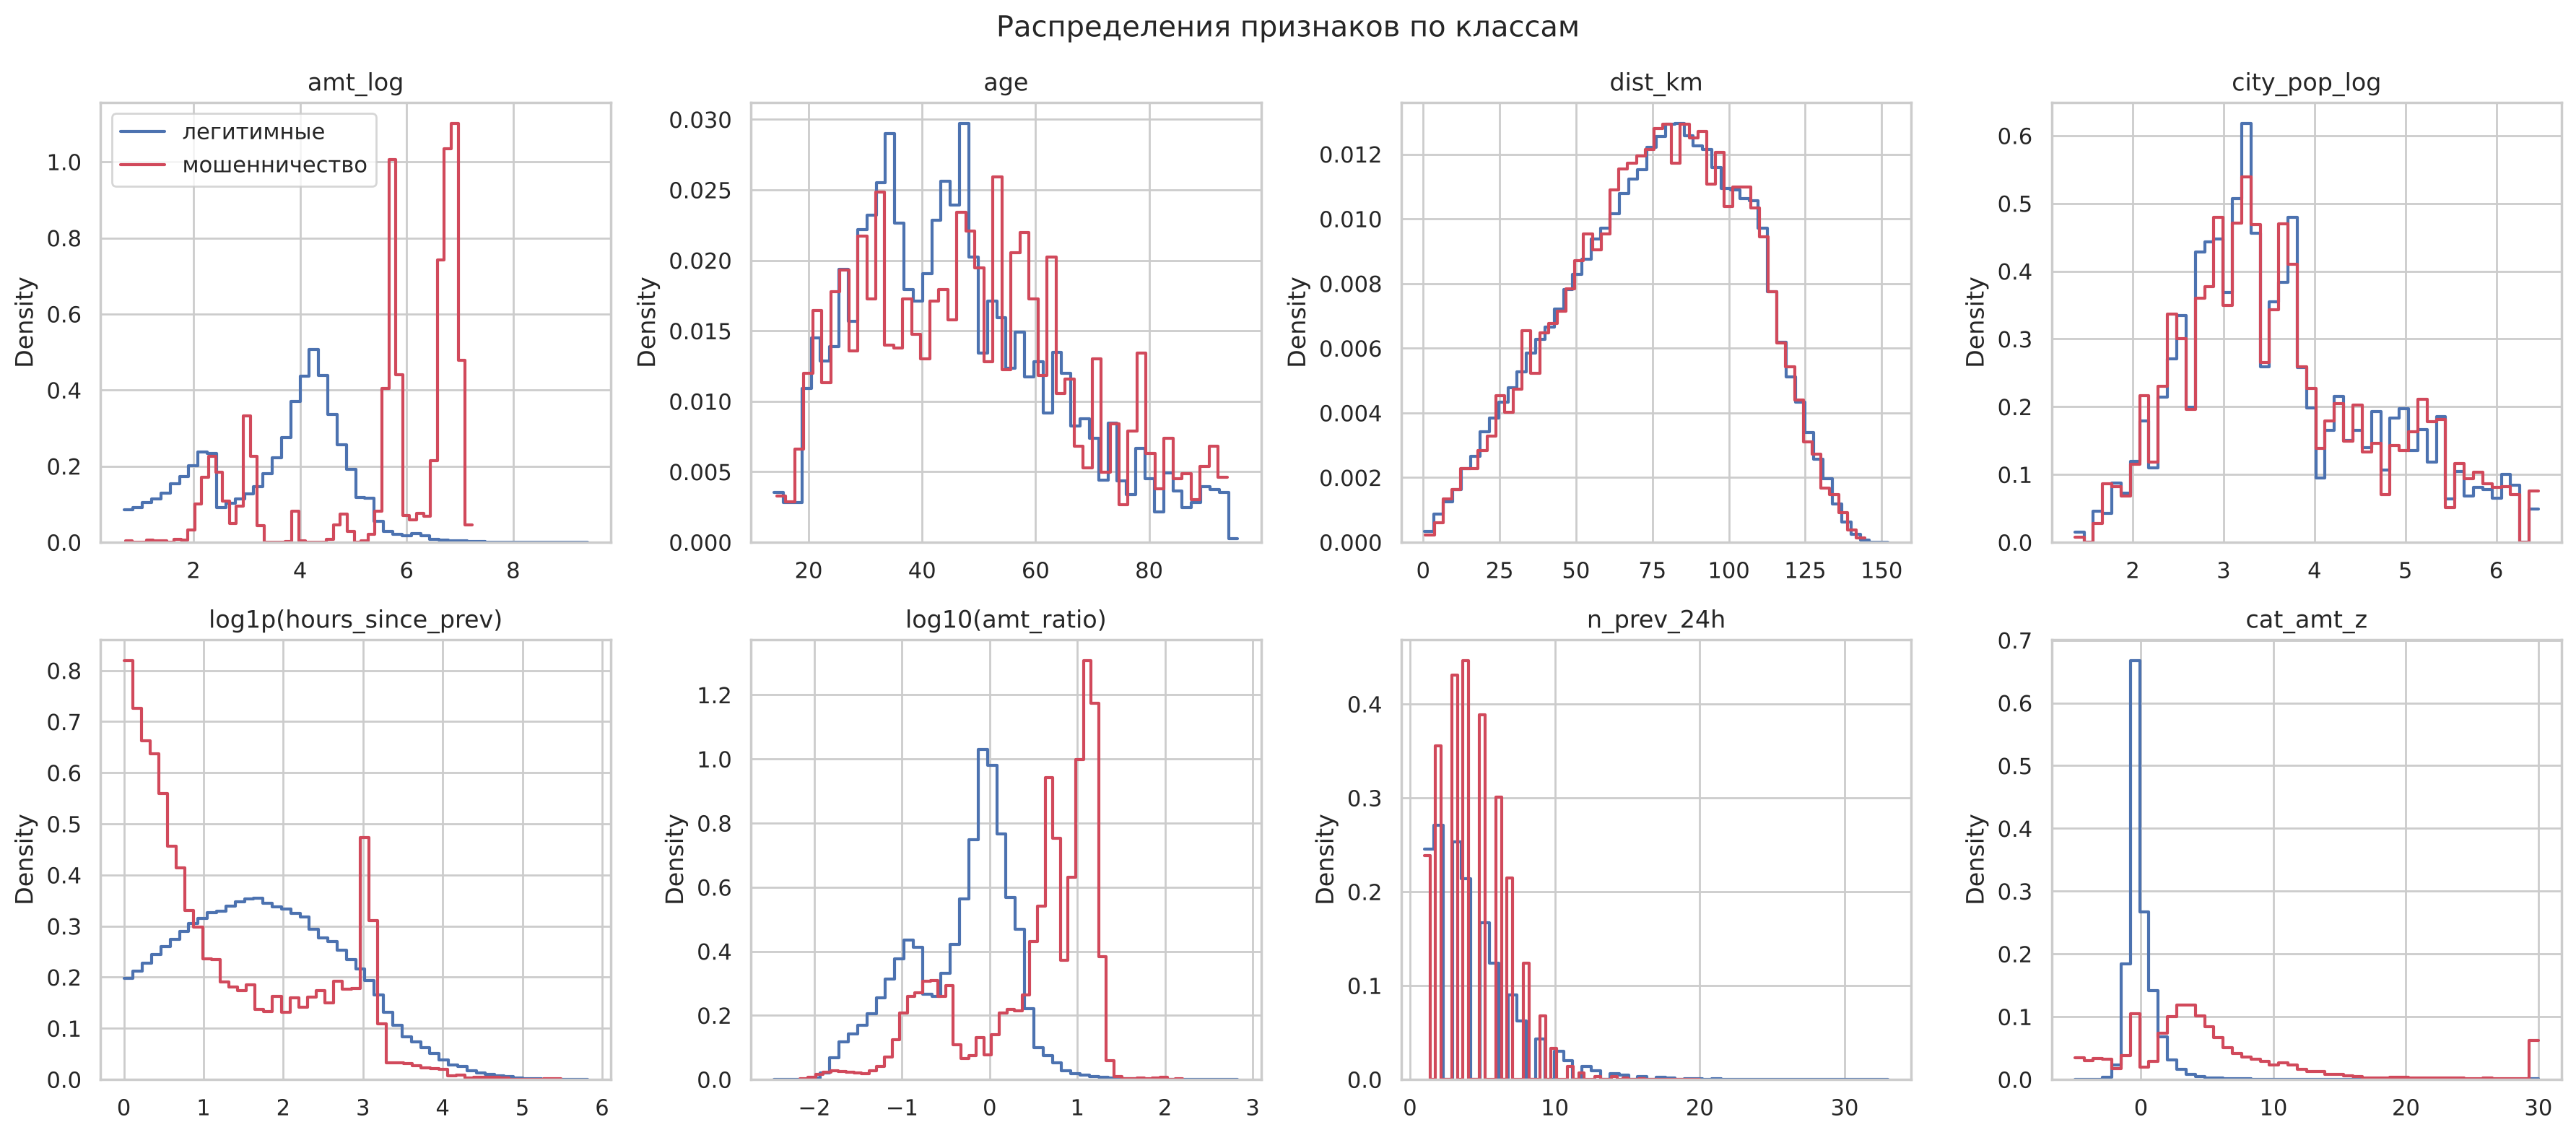

In [21]:
plot_f = ['amt_log', 'age', 'dist_km', 'city_pop_log', 'hours_since_prev', 'amt_ratio', 'n_prev_24h', 'cat_amt_z']
smp = pd.concat([tr[~pos].sample(200_000, random_state=RS), tr[pos]])
smp['hours_since_prev'] = np.log1p(smp['hours_since_prev'])
smp['amt_ratio'] = np.log10(smp['amt_ratio'])
smp['cat_amt_z'] = smp['cat_amt_z'].clip(-5, 30)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), plot_f):
    for cls in [0, 1]:
        sns.histplot(smp.loc[smp['is_fraud'] == cls, c].dropna(), bins=50, stat='density', element='step', fill=False,
                     color=PAL[cls], ax=ax, label=['легитимные', 'мошенничество'][cls])
    ax.set_title({'hours_since_prev': 'log1p(hours_since_prev)', 'amt_ratio': 'log10(amt_ratio)'}.get(c, c))
    ax.set_xlabel('')
axes[0, 0].legend()
plt.suptitle('Распределения признаков по классам')
plt.tight_layout()
plt.show()

## 7. Корреляции

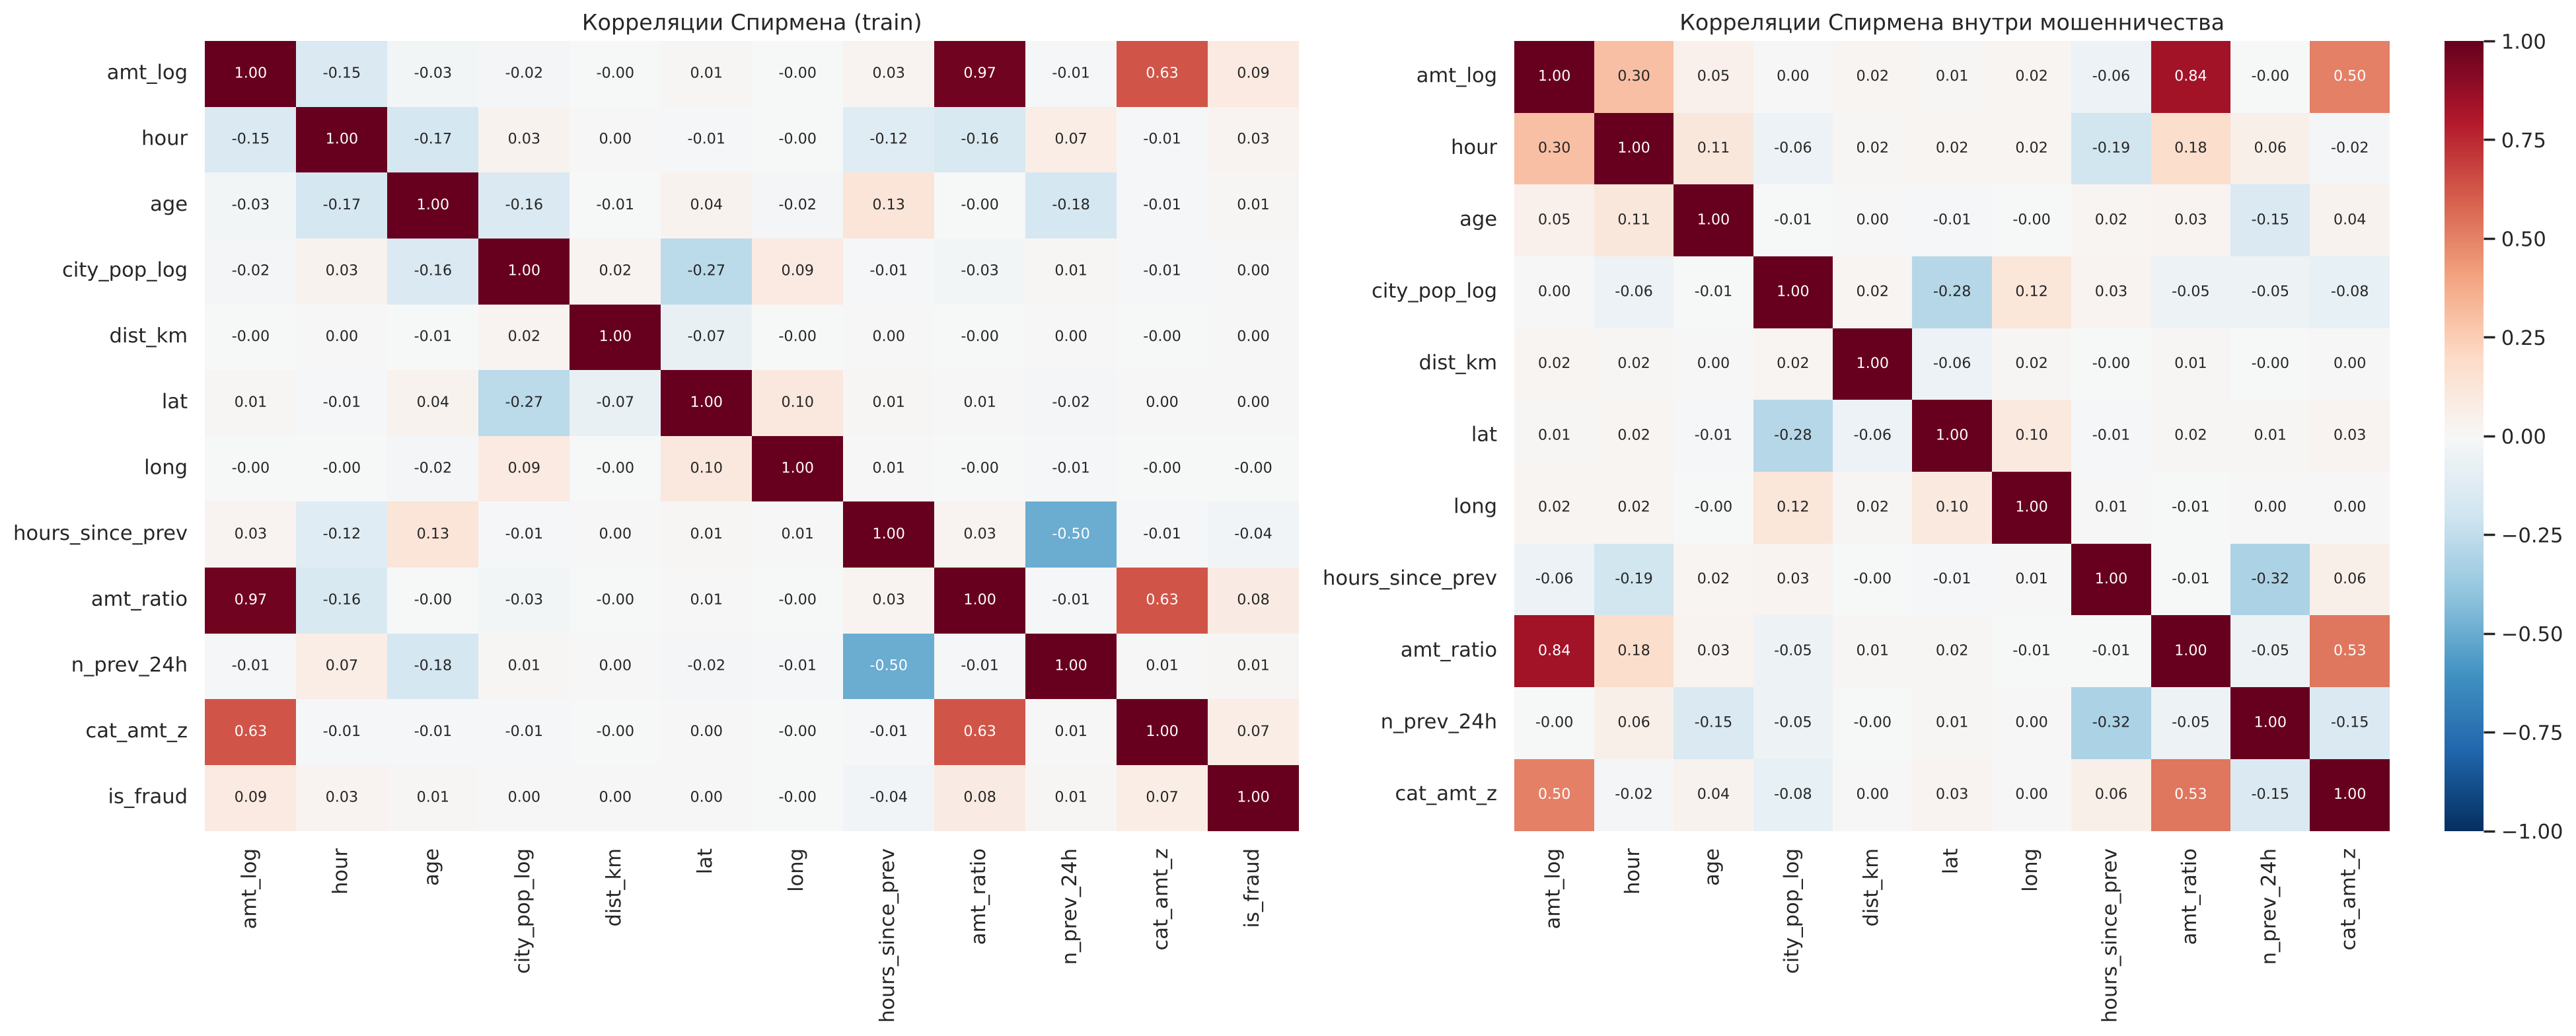

In [22]:
corr_cols = ['amt_log', 'hour', 'age', 'city_pop_log', 'dist_km', 'lat', 'long', 'hours_since_prev', 'amt_ratio', 'n_prev_24h', 'cat_amt_z', 'is_fraud']
cs = tr[corr_cols].sample(400_000, random_state=RS)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cs.corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False, annot_kws={'size': 8})
axes[0].set_title('Корреляции Спирмена (train)')
sns.heatmap(tr.loc[pos, corr_cols[:-1]].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[1], annot_kws={'size': 8})
axes[1].set_title('Корреляции Спирмена внутри мошенничества')
plt.tight_layout()
plt.show()

In [23]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cat_cols = ['category', 'gender', 'state', 'job', 'merchant', 'city']
cv = pd.Series({c: cramers_v(tr[c], tr['is_fraud']) for c in cat_cols}).sort_values(ascending=False)
nun = tr[cat_cols].nunique()
pd.DataFrame({'cramers_v_with_target': cv, 'n_unique': nun}).round(4)

,cramers_v_with_target,n_unique
category,0.0707,14
city,0.2843,894
gender,0.0076,2
job,0.1738,494
merchant,0.0731,693
state,0.0380,51


- Числовые признаки между собой почти не коррелируют, кроме понятных пар: `amt_log` и `amt_ratio` (0.97, средняя сумма карты меняется мало, поэтому отношение почти повторяет сумму), `amt_log` и `cat_amt_z` (0.63), `hours_since_prev` и `n_prev_24h` (-0.50), `city_pop_log` и `lat` (-0.27). Деревьям это не мешает, а для линейных моделей из `amt_log` и `amt_ratio` лучше оставить один.
- Корреляции с таргетом у всех признаков слабые, не больше 0.09 по модулю. Связи с мошенничеством нелинейные (час, U-образная сумма), их видно по ROC-AUC, KS и сводным таблицам, а не по корреляциям.
- Внутри мошенничества появляется связь суммы и часа (0.30), ночное мошенничество в среднем крупнее. А `n_prev_24h` у мошеннических и нормальных операций почти одинаковый (медиана 4), так что частота операций в этом генераторе слабый признак.
- По V Крамера из категориальных признаков с маленьким числом значений с таргетом связана в основном `category`. У `job`, `merchant` и `city` V Крамера завышен из-за большого числа уровней и маленьких групп. Через one-hot их брать нельзя, а при target encoding нужно out-of-fold и сглаживание.

## 8. Попарные распределения

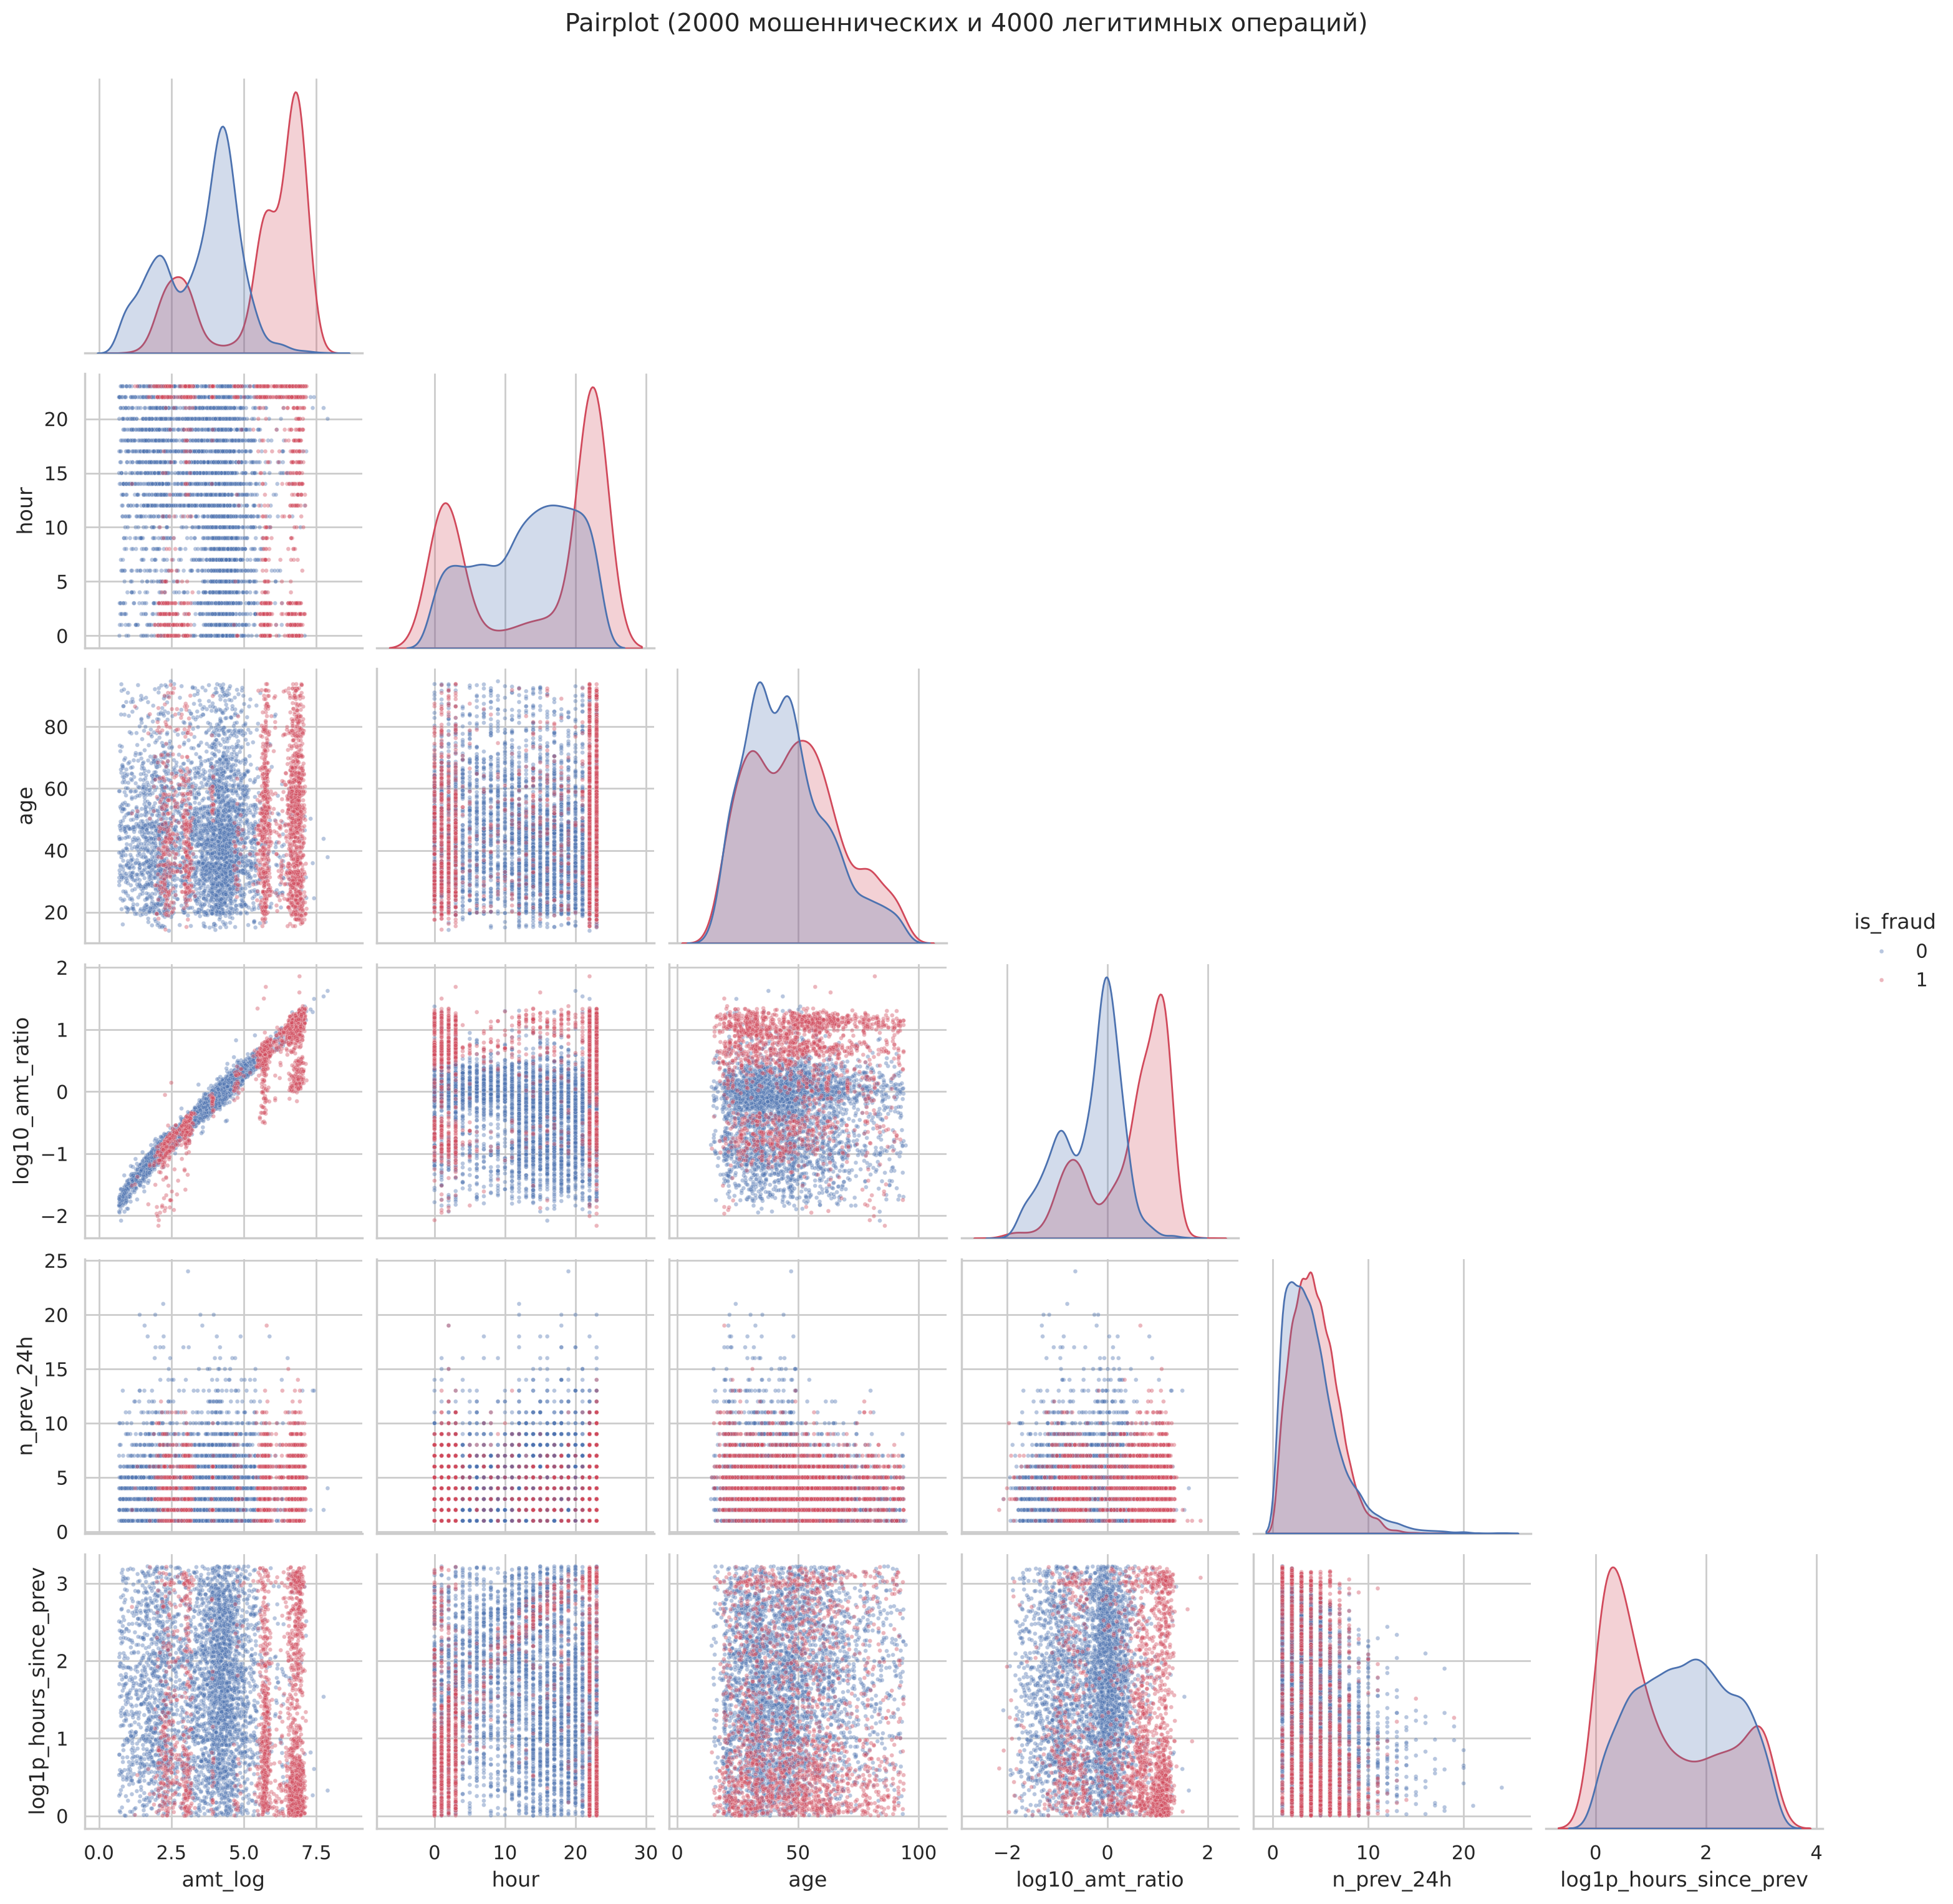

In [24]:
pp_cols = ['amt_log', 'hour', 'age', 'amt_ratio', 'n_prev_24h', 'hours_since_prev']
pp = pd.concat([tr[~pos].sample(4000, random_state=RS), tr[pos].sample(2000, random_state=RS)])[pp_cols + ['is_fraud']].copy()
pp['amt_ratio'] = np.log10(pp['amt_ratio'])
pp['hours_since_prev'] = np.log1p(pp['hours_since_prev'])
pp = pp.rename(columns={'amt_ratio': 'log10_amt_ratio', 'hours_since_prev': 'log1p_hours_since_prev'})
g_ = sns.pairplot(pp.dropna(), hue='is_fraud', palette=PAL, plot_kws={'s': 6, 'alpha': 0.4}, diag_kws={'common_norm': False}, corner=True)
g_.fig.suptitle('Pairplot (2000 мошеннических и 4000 легитимных операций)', y=1.02)
plt.show()

На pairplot мошенничество собирается в компактные области: ночь и крупная сумма, ночь и очень маленькая сумма, большое отношение к средней сумме карты. По одному признаку классы не разделить, но сочетание часа, суммы и отклонения от истории карты отделяет большую часть мошенничества.

## 9. Сводные таблицы

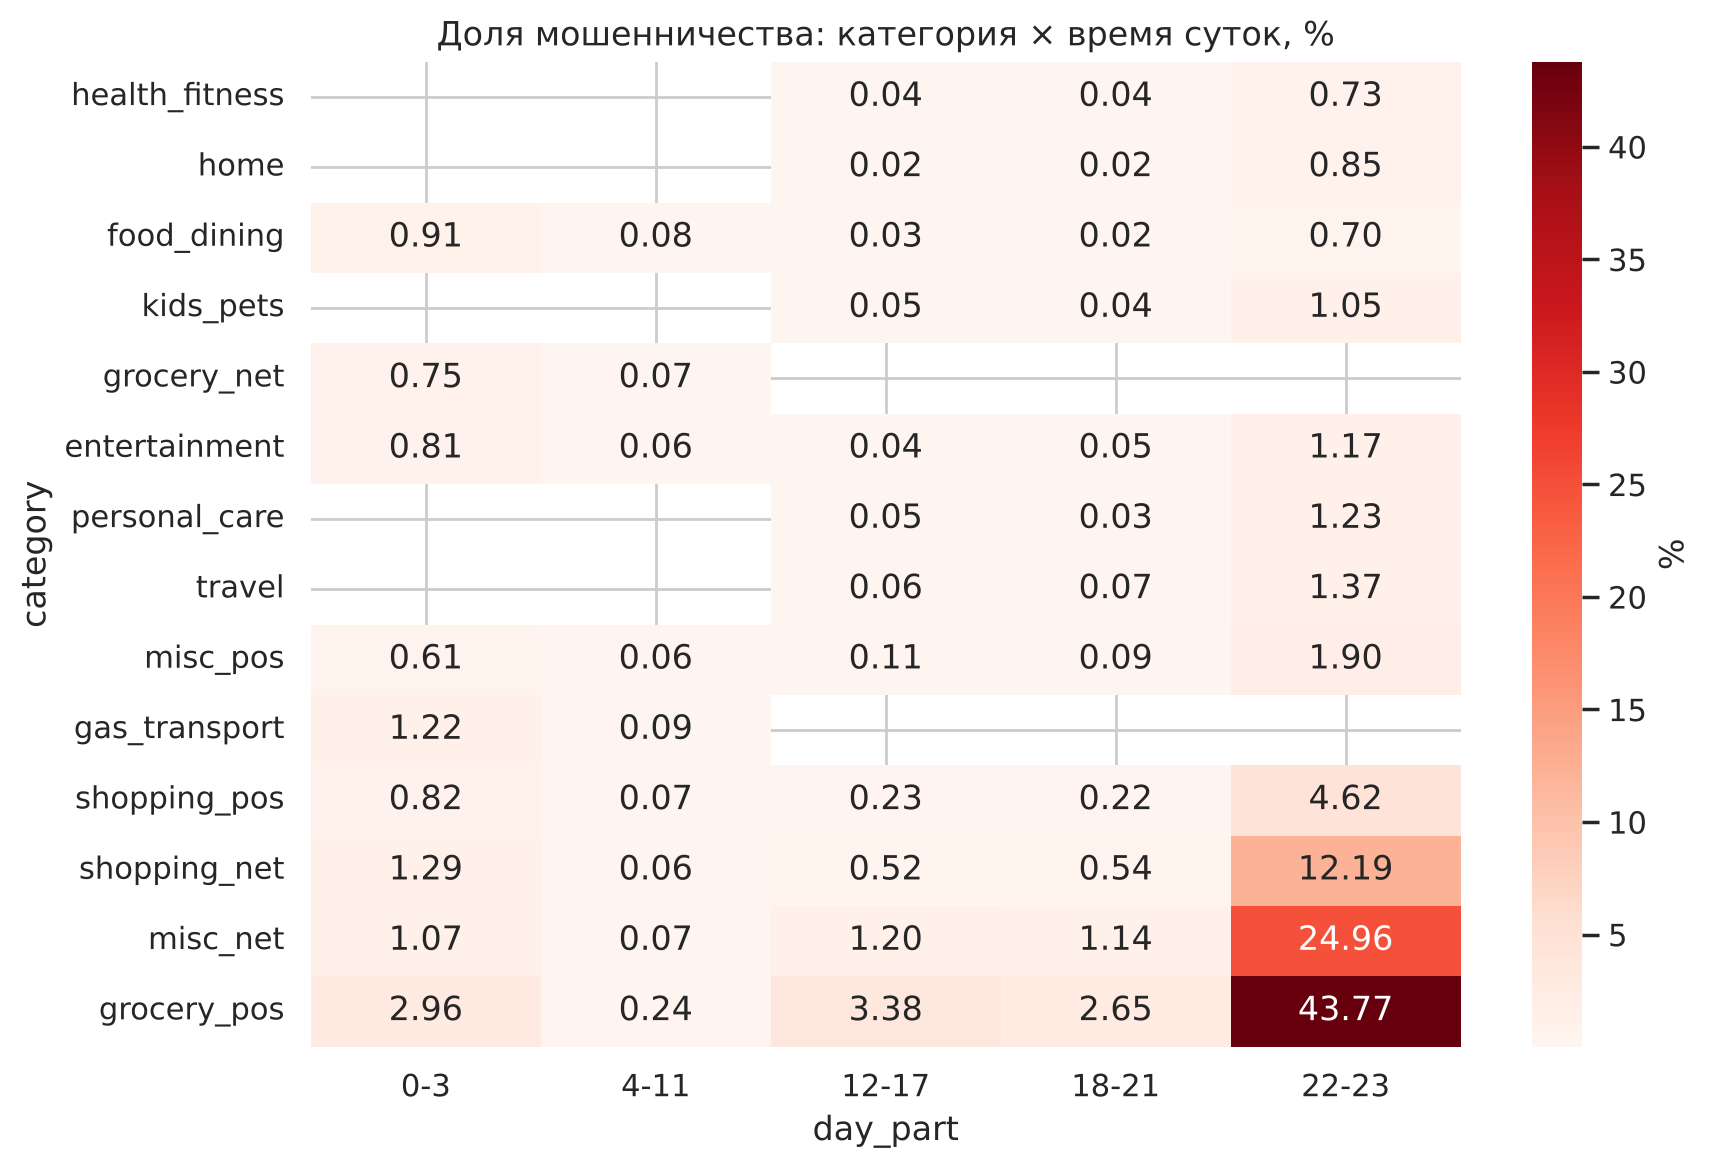

In [25]:
tr['day_part'] = pd.cut(tr['hour'], [-1, 3, 11, 17, 21, 23], labels=['0-3', '4-11', '12-17', '18-21', '22-23'])
pv = pd.pivot_table(tr, index='category', columns='day_part', values='is_fraud', aggfunc='mean', observed=True) * 100
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pv.loc[pv.mean(axis=1).sort_values().index], annot=True, fmt='.2f', cmap='Reds', ax=ax, cbar_kws={'label': '%'})
ax.set_title('Доля мошенничества: категория × время суток, %')
plt.tight_layout()
plt.show()

In [26]:
tr['amt_bin'] = pd.cut(tr['amt'], [0, 10, 50, 100, 300, 600, 1000, 1500, np.inf])
pd.pivot_table(tr, index='amt_bin', columns='gender', values='is_fraud', aggfunc='mean', observed=True).mul(100).round(3).assign(
    n=tr.groupby('amt_bin', observed=True).size())

gender,F,M,n
amt_bin,,,
"(0.0, 10.0]",0.124,0.200,335929
"(10.0, 50.0]",0.353,0.280,336370
"(50.0, 100.0]",0.015,0.008,389483
"(100.0, 300.0]",0.398,0.556,204595
"(300.0, 600.0]",7.181,6.902,19225
"(600.0, 1000.0]",29.439,45.758,7137
"(1000.0, 1500.0]",27.916,46.240,2640
"(1500.0, inf]",0.000,0.000,1296


In [27]:
tr.groupby('age_bin', observed=True).agg(n=('is_fraud', 'size'), fraud_rate=('is_fraud', 'mean'),
                                         median_amt=('amt', 'median'), median_amt_fraud=('amt', lambda s: s[tr.loc[s.index, 'is_fraud'] == 1].median())).round(4)

,n,fraud_rate,median_amt,median_amt_fraud
age_bin,,,,
<25,121688,0.0063,37.10,703.665
25-34,287749,0.0048,51.70,352.720
35-44,272940,0.0043,53.15,336.200
45-54,256553,0.0058,45.89,359.010
55-64,164087,0.0077,42.81,658.570
65-74,100384,0.0059,42.79,753.605
75+,93274,0.0090,42.97,436.750


- В 22–23 часа в `grocery_pos` мошенничество составляет 44% операций, в `misc_net` 25%, в `shopping_net` 12%. Днем почти во всех категориях оно около нуля (кроме `grocery_pos` и `misc_net`).
- Пустые клетки тоже артефакт генератора: некоторые категории бывают только в определенные часы (например, `gas_transport` и `grocery_net` только с 0 до 11, а `home`, `travel`, `health_fitness` только с 12 до 23). Модель может этим воспользоваться, но в реальных данных такого не будет.
- Зависимость от суммы немонотонная: на суммах 600–1500 мошенничество составляет 30–46% операций, на 300–600 около 7%, а на 50–100 и больше 1500 его почти нет.
- Клиенты 75+ и 55–64 чаще становятся жертвами (0.8–0.9% против 0.4–0.5% в 25–44 года), но по возрасту и полу разница намного меньше, чем по времени и сумме.

## 10. Типы аномальных наблюдений

In [28]:
anom_cols = ['amt_log', 'hour', 'age', 'city_pop_log', 'dist_km']
X = tr[anom_cols].to_numpy()
iso_g = IsolationForest(n_estimators=100, max_samples=4096, random_state=RS, n_jobs=-1).fit(X)
tr['iso_global'] = -iso_g.score_samples(X)

anom_cols2 = anom_cols + ['amt_ratio', 'n_prev_24h', 'hours_since_prev', 'cat_amt_z']
X2 = tr[anom_cols2].fillna(tr[anom_cols2].median()).to_numpy()
iso_c = IsolationForest(n_estimators=100, max_samples=4096, random_state=RS, n_jobs=-1).fit(X2)
tr['iso_context'] = -iso_c.score_samples(X2)

res = {}
for name, col in [('глобальные признаки', 'iso_global'), ('+ поведенческие признаки', 'iso_context')]:
    top = tr[col] >= tr[col].quantile(0.99)
    res[name] = {'roc_auc': roc_auc_score(tr['is_fraud'], tr[col]), 'pr_auc': average_precision_score(tr['is_fraud'], tr[col]),
                 'recall_top1%': tr.loc[pos, col].ge(tr[col].quantile(0.99)).mean(), 'precision_top1%': tr.loc[top, 'is_fraud'].mean()}
pd.DataFrame(res).T.round(3)

,roc_auc,pr_auc,recall_top1%,precision_top1%
глобальные признаки,0.865,0.080,0.205,0.119
+ поведенческие признаки,0.906,0.117,0.330,0.191


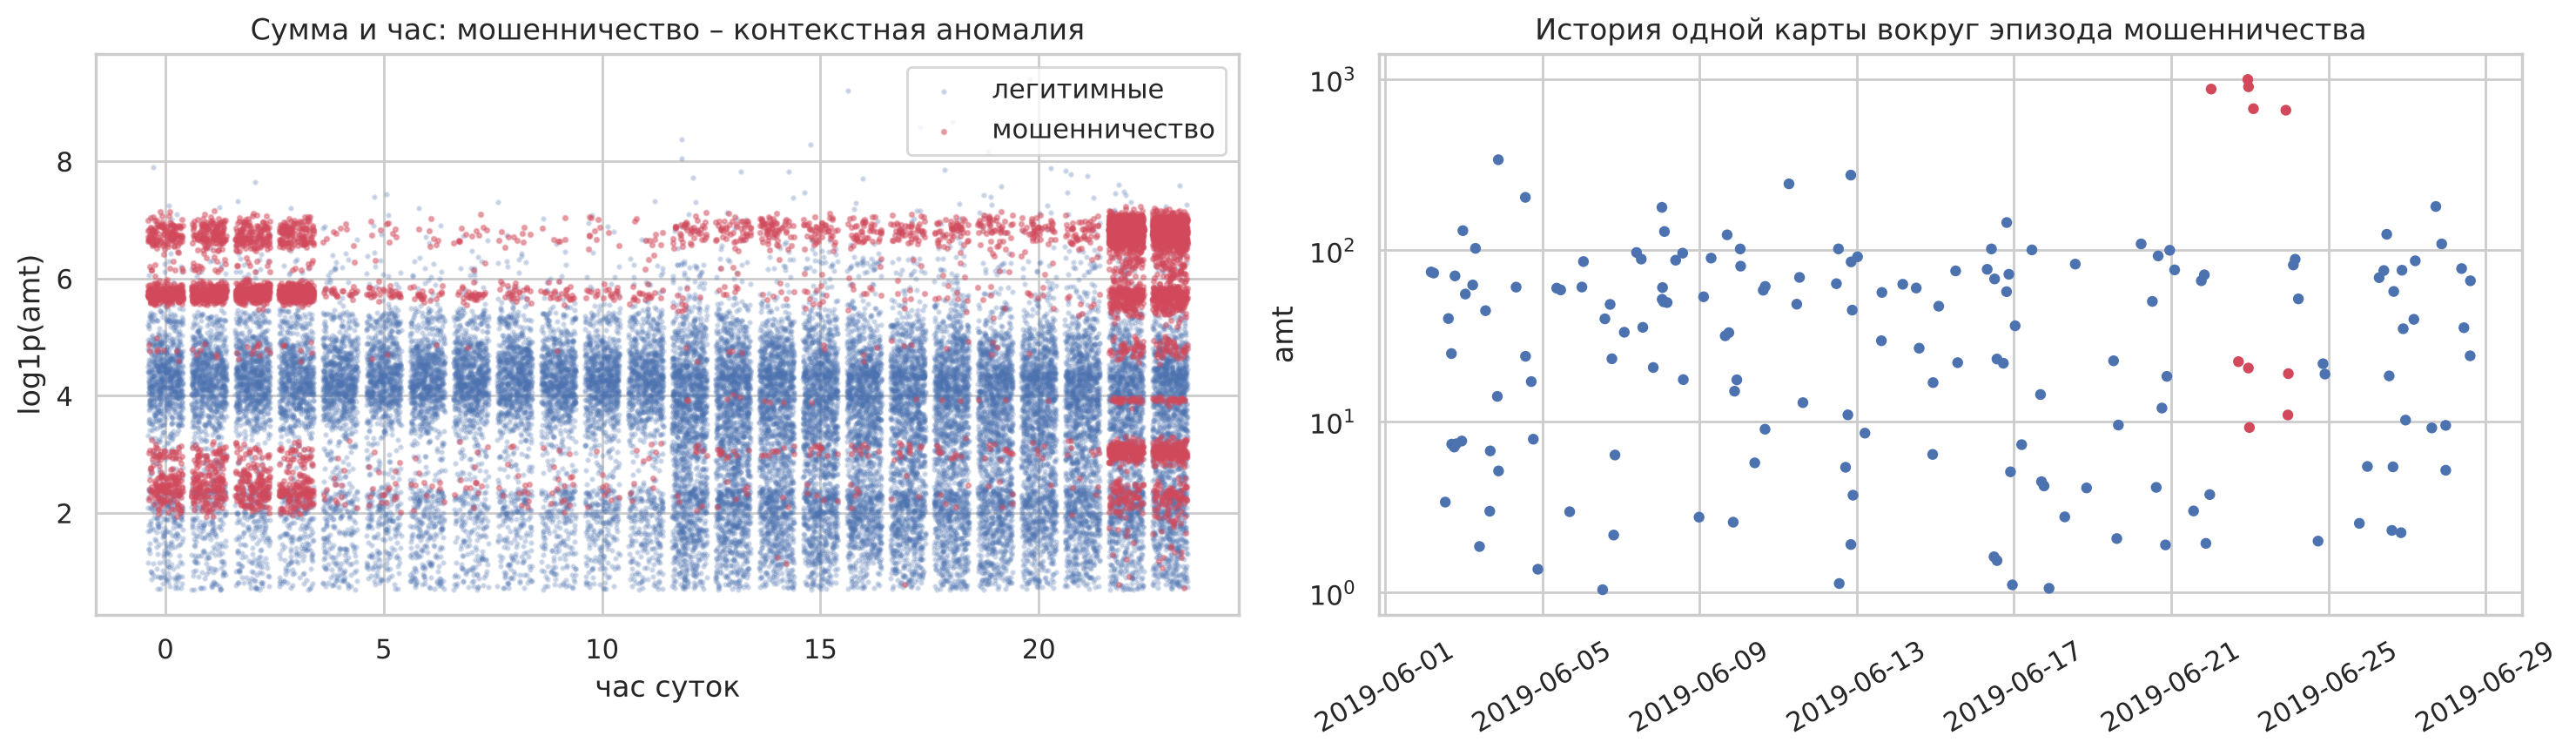

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bg = tr[~pos].sample(30000, random_state=RS)
axes[0].scatter(bg['hour'] + np.random.uniform(-0.4, 0.4, len(bg)), bg['amt_log'], s=2, alpha=0.2, color=PAL[0], label='легитимные')
fr = tr[pos]
axes[0].scatter(fr['hour'] + np.random.uniform(-0.4, 0.4, len(fr)), fr['amt_log'], s=3, alpha=0.4, color=PAL[1], label='мошенничество')
axes[0].set_xlabel('час суток')
axes[0].set_ylabel('log1p(amt)')
axes[0].set_title('Сумма и час: мошенничество – контекстная аномалия')
axes[0].legend(loc='upper right')
fc_ = tr.loc[pos, 'cc_num'].unique()
ex = tr[tr['cc_num'] == tr[tr['cc_num'].isin(fc_)]['cc_num'].value_counts().index[0]]
w = ex[(ex['ts'] >= ex.loc[ex['is_fraud'] == 1, 'ts'].min() - pd.Timedelta(days=20)) & (ex['ts'] <= ex.loc[ex['is_fraud'] == 1, 'ts'].max() + pd.Timedelta(days=5))]
axes[1].scatter(w['ts'], w['amt'], c=np.where(w['is_fraud'] == 1, PAL[1], PAL[0]), s=12)
axes[1].set_yscale('log')
axes[1].set_title('История одной карты вокруг эпизода мошенничества')
axes[1].set_ylabel('amt')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [30]:
ep = tr[pos].groupby('cc_num').agg(n_fraud=('is_fraud', 'size'), start=('ts', 'min'), end=('ts', 'max'))
ep['days'] = (ep['end'] - ep['start']).dt.total_seconds() / 86400
print('Карт с мошенничеством:', len(ep), 'из', tr['cc_num'].nunique())
print('Мошеннических операций на карту, медиана:', ep['n_fraud'].median(), 'максимум:', ep['n_fraud'].max())
print('Длительность эпизода, дней, медиана:', round(ep['days'].median(), 2), '90-й перцентиль:', round(ep['days'].quantile(0.9), 2))
after = tr.merge(ep[['end']], left_on='cc_num', right_index=True)
print('Карт, у которых после эпизода есть легитимные операции:', after.loc[after['ts'] > after['end'], 'cc_num'].nunique())

Карт с мошенничеством: 762 из 983
Мошеннических операций на карту, медиана: 10.0 максимум: 19
Длительность эпизода, дней, медиана: 1.88 90-й перцентиль: 1.97


Карт, у которых после эпизода есть легитимные операции: 682


Какие аномалии есть в Sparkov:

1. Глобальные аномалии, то есть операции с необычными значениями самих признаков (например, очень большая сумма). Тут они почти всегда нормальные, самые крупные суммы в датасете не мошеннические. Из-за них будут ложные срабатывания.
2. Контекстные аномалии, это основная форма мошенничества. Сумма 300–1000 сама по себе обычная, но необычная ночью, в этой категории и для этой карты. На левом графике мошенничество занимает ночные области, где нормальных операций мало.
3. Коллективные аномалии. Мошенничество идет эпизодами: по карте проходит серия в среднем из 10 операций примерно за 2 дня (правый график), а потом 682 из 762 карт снова используются нормально.

Isolation Forest на обычных признаках работает слабо (PR-AUC 0.08, в top 1% попадает 20% мошенничества при precision 12%). Если добавить признаки отклонения от истории карты, все метрики растут (PR-AUC 0.12, в top 1% уже 33% мошенничества), и это без всяких меток. Получается, что на этом датасете главное это сделать хорошие контекстные признаки, а выбор модели уже вторичен.

## 11. Временная структура, сдвиг и потенциальные утечки

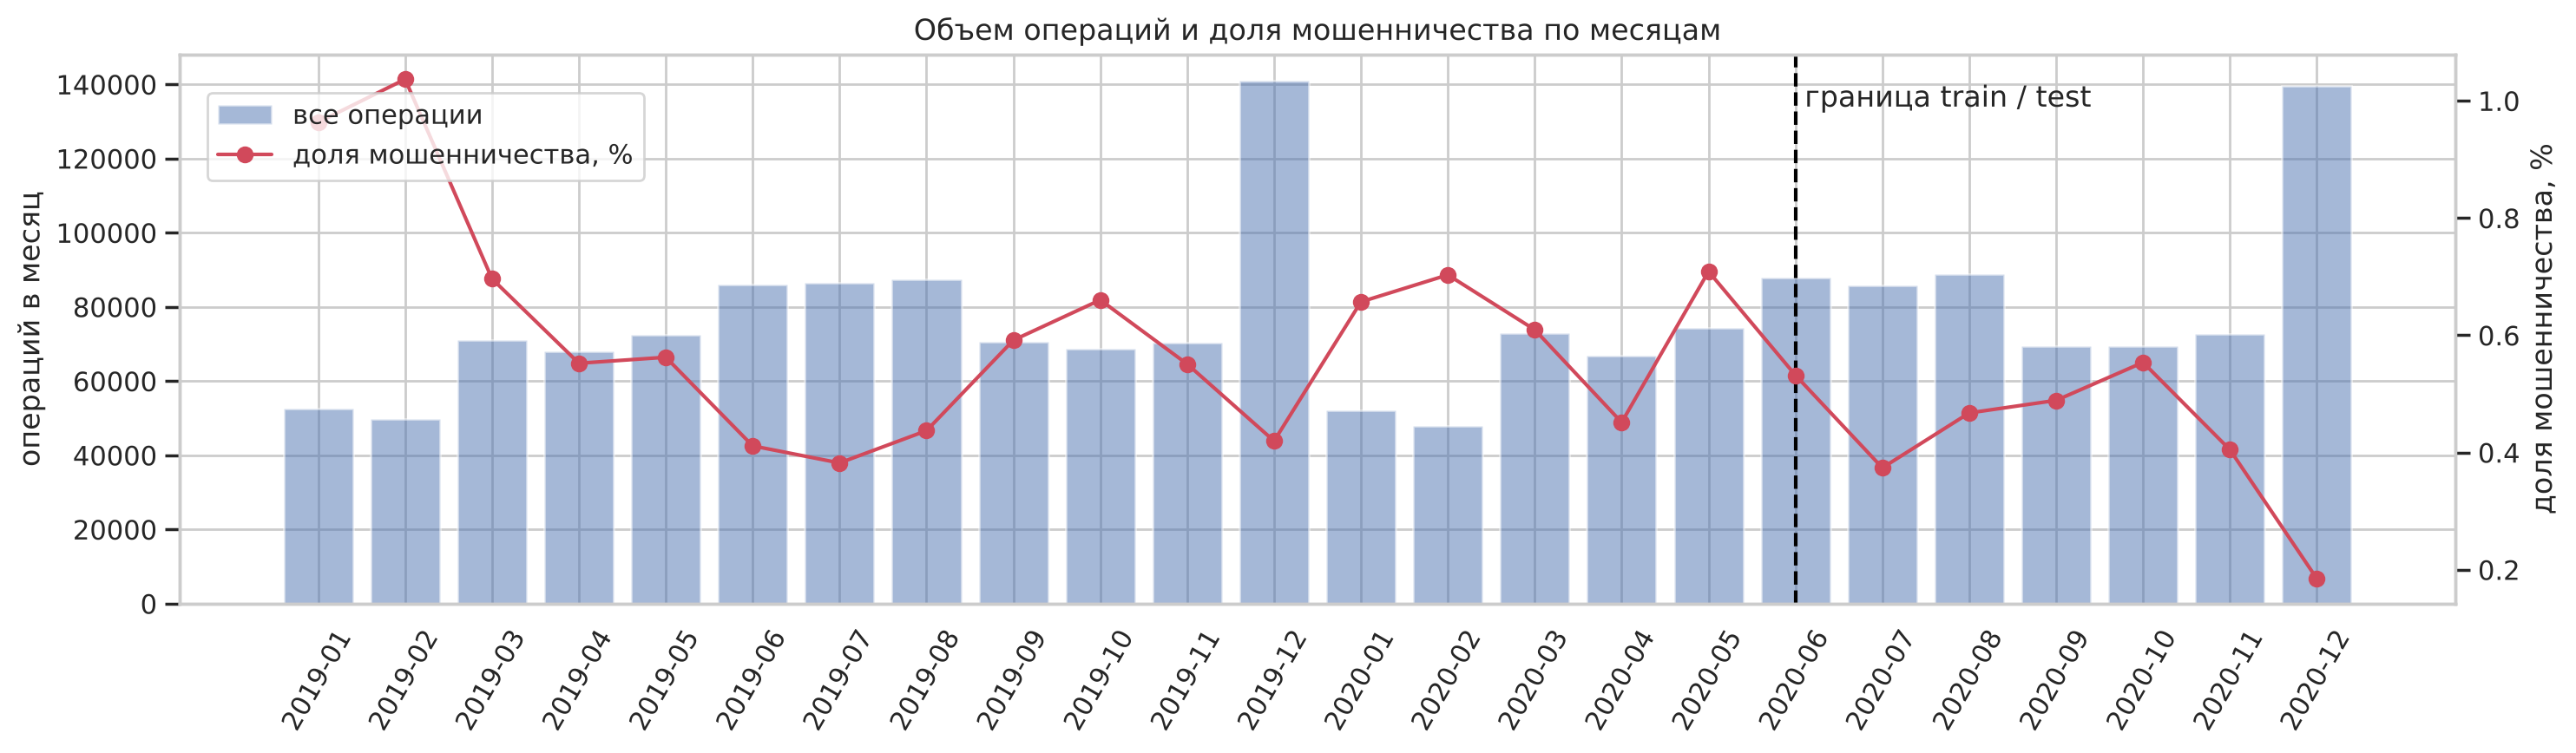

In [31]:
te['ts'] = pd.to_datetime(te['trans_date_trans_time'])
allm = pd.concat([tr[['ts', 'is_fraud']].assign(part='train'), te[['ts', 'is_fraud']].assign(part='test')])
mm = allm.groupby(allm['ts'].dt.to_period('M')).agg(n=('is_fraud', 'size'), n_fraud=('is_fraud', 'sum'), fraud_rate=('is_fraud', 'mean'))
fig, ax1 = plt.subplots(figsize=(15, 4.5))
xs = mm.index.astype(str)
ax1.bar(xs, mm['n'], color=PAL[0], alpha=0.5, label='все операции')
ax1.set_ylabel('операций в месяц')
ax2 = ax1.twinx()
ax2.plot(xs, mm['fraud_rate'] * 100, color=PAL[1], marker='o', label='доля мошенничества, %')
ax2.set_ylabel('доля мошенничества, %')
ax2.grid(False)
b = list(xs).index('2020-06')
ax1.axvline(b, color='black', ls='--')
ax1.text(b, mm['n'].max() * 0.95, ' граница train / test')
ax1.tick_params(axis='x', rotation=60)
ax1.set_title('Объем операций и доля мошенничества по месяцам')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.88))
plt.tight_layout()
plt.show()

In [32]:
te['merchant'] = te['merchant'].str.replace('fraud_', '', regex=False)
cards_tr, cards_te = set(tr['cc_num']), set(te['cc_num'])
print('Карт в train:', len(cards_tr), 'в test:', len(cards_te), 'общих:', len(cards_tr & cards_te))
print('Мерчантов в test, которых нет в train:', len(set(te['merchant']) - set(tr['merchant'])))
fr_tr = set(tr.loc[pos, 'cc_num'])
fr_te = set(te.loc[te['is_fraud'] == 1, 'cc_num'])
print('Карт с мошенничеством в train:', len(fr_tr), 'в test:', len(fr_te), 'общих:', len(fr_tr & fr_te))
drift = pd.DataFrame({'train': tr.groupby('category')['is_fraud'].mean(), 'test': te.groupby('category')['is_fraud'].mean()}) * 100
drift['ratio'] = drift['test'] / drift['train']
drift.sort_values('ratio').round(3)

Карт в train: 983 в test: 924 общих: 908


Мерчантов в test, которых нет в train: 0
Карт с мошенничеством в train: 762 в test: 218 общих: 4


,train,test,ratio
category,,,
gas_transport,0.469,0.273,0.582
shopping_pos,0.723,0.428,0.592
entertainment,0.248,0.147,0.594
kids_pets,0.211,0.133,0.631
grocery_pos,1.410,0.923,0.655
misc_pos,0.314,0.208,0.664
misc_net,1.446,0.976,0.675
shopping_net,1.756,1.211,0.690
grocery_net,0.295,0.211,0.716


In [33]:
rng = np.random.default_rng(RS)
idx = rng.permutation(len(tr))
rand_test = tr.iloc[idx[: len(tr) // 5]]
rand_train = tr.iloc[idx[len(tr) // 5:]]
ep_cards = set(rand_test.loc[rand_test['is_fraud'] == 1, 'cc_num'])
seen = set(rand_train.loc[rand_train['is_fraud'] == 1, 'cc_num'])
print('Случайное разбиение 80/20: доля мошеннических карт теста, чей эпизод уже есть в train:', round(len(ep_cards & seen) / len(ep_cards), 3))

Случайное разбиение 80/20: доля мошеннических карт теста, чей эпизод уже есть в train: 1.0


Объем операций сезонный: пик в декабре (около 140 тыс. операций, в два раза больше обычного) и минимум в январе–феврале. Доля мошенничества по месяцам от 0.18% (декабрь 2020) до 1.04% (февраль 2019), в декабре количество мошеннических операций не растет вместе с объемом. В test доля мошенничества ниже во всех 14 категориях (в 1.1–1.7 раза).

Еще важная вещь: из 218 карт с мошенничеством в test только у 4 было мошенничество в train. То есть тест проверяет, найдем ли мы новые эпизоды у новых жертв. А при случайном разбиении, из-за того что мошенничество идет эпизодами, для 100% мошеннических карт из тестовой части в train уже есть операции из того же эпизода.

Где может быть утечка:
- Случайное разбиение: эпизод мошенничества одной карты попадает и в train, и в test, и модель "узнает" его по карте, времени и мерчанту. Разбиваем по времени и дополнительно проверяем с группами по `cc_num`.
- `cc_num`, `trans_num`, `first`, `last`, `street` это id и персональные данные, модель будет запоминать конкретных клиентов. Как признаки не используем, `cc_num` нужен только для агрегатов и групп.
- Поведенческие агрегаты, если считать их по всей истории, будут включать будущее и сам эпизод. Считаем только по прошлым операциям (`shift`, `closed="left"`).
- Target encoding `merchant`, `job`, `city`: много уровней, маленькие группы, легко получить утечку таргета. Делаем out-of-fold со сглаживанием и только по прошлым данным.
- `unix_time` сдвинут на 7 лет. Используем `trans_date_trans_time`.
- Пороги и нормировки по категориям, посчитанные на всех данных, включают test. Считаем только на train.

## 12. Схема разбиения данных

In [34]:
val_start = pd.Timestamp('2020-03-01')
parts = pd.concat([
    tr.loc[tr['ts'] < val_start, ['ts', 'is_fraud', 'cc_num']].assign(split='train'),
    tr.loc[tr['ts'] >= val_start, ['ts', 'is_fraud', 'cc_num']].assign(split='valid'),
    te[['ts', 'is_fraud', 'cc_num']].assign(split='test'),
], ignore_index=True)
parts.groupby('split', sort=False).agg(n=('is_fraud', 'size'), n_fraud=('is_fraud', 'sum'), fraud_rate=('is_fraud', 'mean'),
                                       fraud_cards=('cc_num', lambda s: s[parts.loc[s.index, 'is_fraud'].to_numpy() == 1].nunique()),
                                       date_from=('ts', 'min'), date_to=('ts', 'max'))

,n,n_fraud,fraud_rate,fraud_cards,date_from,date_to
split,,,,,,
train,1024843,5899,0.005756,597,2019-01-01 00:00:18,2020-02-28 23:59:45
valid,271832,1607,0.005912,166,2020-03-01 00:02:20,2020-06-21 12:13:37
test,555719,2145,0.003860,218,2020-06-21 12:14:25,2020-12-31 23:59:34


Как разбиваем Sparkov:
- test это авторский файл `fraudTest.csv` (с 21.06.2020 по 31.12.2020), на нем оцениваем один раз в конце
- train это операции с 01.01.2019 по 29.02.2020, validation с 01.03.2020 по 21.06.2020 (подбор гиперпараметров и порога)
- поведенческие признаки считаем по всей истории карты, но только по прошлым операциям, поэтому для validation и test можно брать историю из train, утечки таргета не будет
- для кросс-валидации внутри train используем `TimeSeriesSplit`, а чтобы проверить перенос на новых клиентов, еще `GroupKFold` по `cc_num`
- в test доля мошенничества ниже, поэтому порог выбираем на validation, а результаты при выбранном пороге отдельно проверяем при разной доле класса

## 13. Выводы

1. 1.85 млн синтетических операций по картам за 2019–2020, 983 карты, 693 мерчанта, 14 категорий. Мошенничества 0.58% в train и 0.39% в test. Дисбаланс мягче, чем в ULB и PaySim, но между периодами доля меняется в 1.5 раза.
2. Пропуски только в `merch_zipcode` (15%). Похоже, что индекс не нашелся по случайным координатам мерчанта: пропусков больше в малонаселенных западных штатах и у океана, и с таргетом, категорией и суммой они не связаны. Столбец удаляем, он дублирует координаты.
3. `unix_time` сдвинут на 7 лет (берем `trans_date_trans_time`), у всех мерчантов лишний префикс `fraud_` (удаляем). Невозможных значений и дубликатов нет, данные клиента внутри карты не противоречат друг другу.
4. У суммы тяжелый хвост, но самые крупные операции нормальные, мошенническая сумма не больше 1376. Выбросы оставляем, сумму берем в логарифме и относительно категории и истории карты.
5. Главные признаки это время суток (в 22–3 часа мошенничества в 15–25 раз больше), сумма (зависимость немонотонная, ROC-AUC 0.84), категория (`shopping_net`, `misc_net`, `grocery_pos`) и признаки по истории карты: отношение суммы к средней по карте и к истории в категории (ROC-AUC около 0.80), время с предыдущей операции. Частота операций за 24 часа, демография и география связаны с таргетом слабо, расстояние до мерчанта из-за генератора вообще ничего не дает. Еще нашли артефакт: некоторые категории бывают только днем или только ночью.
6. Мошенничество тут в основном контекстная и коллективная аномалия: серия около 10 операций по одной карте примерно за 2 дня с необычными для карты суммами и в ночное время. Глобальные выбросы в основном нормальные. Isolation Forest с поведенческими признаками работает заметно лучше, чем на исходных.
7. Случайное разбиение использовать нельзя: при нем все эпизоды мошенничества из теста частично попадают в train, а в авторском временном тесте почти все мошеннические карты новые. Разбиваем по времени (train до марта 2020, validation с марта по июнь 2020, test это авторский файл), агрегаты считаем только по прошлому, target encoding делаем out-of-fold.

Что дальше: на Sparkov будем делать поведенческие признаки и интерпретацию модели (SHAP по понятным признакам: время, сумма, категория, отклонение от истории). Еще проверим, насколько выигрыш XGBoost над методами поиска аномалий объясняется именно контекстными признаками и как меняются precision и recall при выбранном пороге, когда доля мошенничества в test ниже, чем в train.